# Session 3, Part 2 (Finger-tapping sequence learning): rounds, learning and a new pattern

**Protocol** (from the session notes):

| Phase | Rounds | What |
|---|---|---|
| Still baseline | | 30 s sitting still |
| Practice pattern **F A D S F D S** | 1–13 | 15 s tapping, 10 s rest, repeated |
| New pattern **S A S D F S A** | 14–17 | 15 s tapping, 10 s rest, repeated (cough during round 14) |

F, A, D and S are left-hand keys, so the tapping was done with the left hand (motor activity
over the right hemisphere, C4).

**Hypotheses:**
1. **Learning:** as the practice pattern becomes familiar it needs less effort, so frontal theta
   should be **lower** and parietal alpha **higher** in late practice (rounds 10–13) than early
   practice (rounds 1–4).
2. **New pattern:** switching to an unfamiliar pattern should need more effort again, so theta
   should be **higher** and alpha **lower** in rounds 14–17 than in late practice (rounds 10–13).

**Why hypothesis 2 is the stronger test:** "early vs late" practice is also "fresh vs tired",
and fatigue moves theta and alpha too. The new-pattern rounds come *after* late practice, so
fatigue would push them the same way as late practice. If theta rises again for the new pattern,
that's effort, not fatigue.

**Same recording setup as Part 1:** Fz is dead (saturated for the whole session), so frontal
theta is measured at **F3+F4**; M1/M2 are excluded; all analysis is average-referenced;
sampled at 1000 Hz. p-values are descriptive only.

Shared analysis code: `processing/analysis.py` and `processing/cleaning.py`.

In [1]:
import sys
from datetime import timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

REPO_ROOT = Path.cwd().resolve()
while not (REPO_ROOT / "processing").is_dir():
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT))

from processing import load_session
from processing.analysis import (
    band_filter, periodic_metrics, periodic_workload_comparison, plot_fooof_fits, plot_periodic_bars,
    plot_quality, plot_relative_bars, plot_segments, plot_spectra, roi_spectrum, window_spectra,
)
from processing.cleaning import ica_clean, prepare

plt.rcParams["figure.dpi"] = 72

SESSION_DIR = REPO_ROOT / "data" / "Session 3_ pt2"
BAD_CHANNELS = ["Fz", "M1", "M2"]   # Fz saturated (no contact); mastoids noisy
THETA_SITE, THETA_CHANNELS = "F3+F4", ["F3", "F4"]   # stands in for Fz
ALPHA_SITE = "Pz"
LOCAL_UTC_OFFSET = timedelta(hours=-5)   # EST

# Session notes (times on the notes' clock, PM)
NOTES = {"baseline": ("7:24:51.920", "7:25:21.921"), "cough": "7:30:58", "end": "7:32:27.019"}
ROUND_TIMES = """
7:25:21.921 7:25:36.927
7:25:46.929 7:26:01.930
7:26:11.934 7:26:26.936
7:26:36.938 7:26:51.940
7:27:01.943 7:27:16.944
7:27:26.948 7:27:41.951
7:27:51.954 7:28:06.955
7:28:16.959 7:28:31.960
7:28:41.963 7:28:56.965
7:29:06.968 7:29:21.970
7:29:31.975 7:29:46.977
7:29:56.981 7:30:11.984
7:30:21.986 7:30:36.989
7:30:46.992 7:31:01.994
7:31:11.999 7:31:27.000
7:31:37.004 7:31:52.008
7:32:02.012 7:32:17.013
"""
PATTERN = ["practice"] * 13 + ["new"] * 4
GROUPS = {"Early practice (rounds 1–4)": range(0, 4), "Middle practice (rounds 5–9)": range(4, 9),
          "Late practice (rounds 10–13)": range(9, 13), "New pattern (rounds 14–17)": range(13, 17)}

In [2]:
session = load_session(SESSION_DIR)
recording = session.segments[0]
start_local = pd.Timestamp(session.raw.info["meas_date"].replace(tzinfo=None) + LOCAL_UTC_OFFSET)


def notes_seconds(clock):
    """Seconds from the start of the recording for an h:mm:ss(.fff) PM time on the notes' clock."""
    h, rest = clock.split(":", 1)
    return (pd.Timestamp(f"{start_local:%Y-%m-%d} {int(h) + 12}:{rest}") - start_local).total_seconds()


rounds_notes = np.array([[notes_seconds(a), notes_seconds(b)] for a, b in (l.split() for l in ROUND_TIMES.strip().splitlines())])
baseline_notes = np.array([notes_seconds(t) for t in NOTES["baseline"]])
print(f"Recording: {start_local:%H:%M:%S} to {start_local + timedelta(seconds=recording.times[-1]):%H:%M:%S} "
      f"(eego clock), {recording.times[-1]:.1f} s at {session.sfreq:g} Hz; {len(rounds_notes)} rounds in the notes")

Recording: 19:24:29 to 19:32:14 (eego clock), 465.5 s at 1000 Hz; 17 rounds in the notes


## 1. Aligning the notes with the recording

The notes' clock and the eego laptop's clock differ. The notes give the rounds to the
millisecond, so the offset can be fitted from the data: during each 15 s round the participant
taps and holds still, and during each 10 s rest they blink and look around. That makes eye
activity at Fp1/Fp2 (1–4 Hz) drop during rounds, and motor beta (13–30 Hz at C3/Cz/C4) also
drops while the fingers move. The offset that best lines the round schedule up with both signals
is used. The cough gives a rough cross-check.

**Why this plot:** every per-round result depends on the rounds being placed correctly, so
this shows how well the schedule fits the data and how sharply the offset is determined.

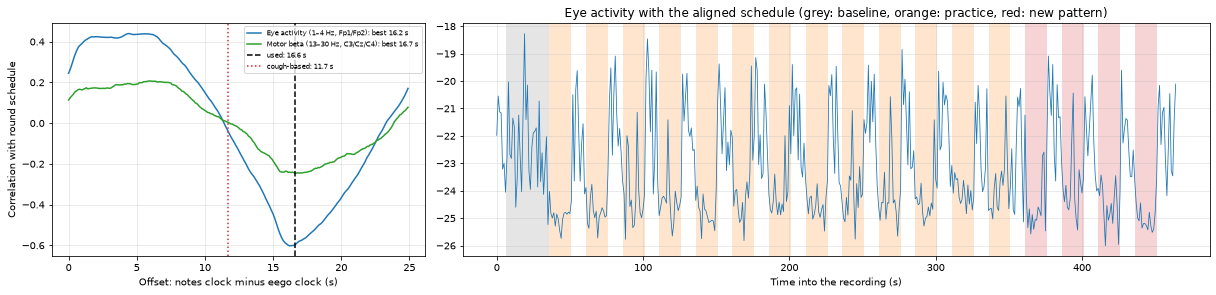

Offset used: 16.6 s (notes clock ahead). Baseline 6.0–36.0 s; round 1 starts 36.0 s; round 17 ends 451.1 s (recording ends 465.5 s)
Cough: noted time → 372.1 s; largest burst at 377 s. Excluded: 371–380 s


In [3]:
prepared = prepare(recording, BAD_CHANNELS)
STEP = 0.1  # s


def log_envelope(band, channels):
    x = prepared.copy().pick(channels).filter(*band, verbose="error").apply_hilbert(envelope=True, verbose="error").get_data()
    x = np.log(x ** 2).mean(axis=0)
    n = int(STEP * session.sfreq)
    return x[: len(x) // n * n].reshape(-1, n).mean(axis=1)


signals = {"Eye activity (1–4 Hz, Fp1/Fp2)": log_envelope((1, 4), ["Fp1", "Fp2"]),
           "Motor beta (13–30 Hz, C3/Cz/C4)": log_envelope((13, 30), ["C3", "Cz", "C4"])}
t = np.arange(len(next(iter(signals.values())))) * STEP
offsets = np.arange(0, 25, STEP)


def fit(signal):
    corr = []
    for off in offsets:
        box = np.zeros_like(t)
        for a, b in rounds_notes - off:
            box[(t >= a) & (t < b)] = 1
        m = (t >= rounds_notes[0, 0] - off - 10) & (t <= rounds_notes[-1, 1] - off + 5)
        corr.append(np.corrcoef(signal[m], box[m])[0, 1])
    return np.array(corr)


fits = {k: fit(v) for k, v in signals.items()}
combined = sum(c / c.min() for c in fits.values())
OFFSET = round(float(offsets[np.argmax(combined)]), 1)

# Cough cross-check: largest all-channel burst after the first minute
level = np.median(np.abs(recording.copy().filter(1, 40, verbose="error").get_data()), axis=0)
sf = int(session.sfreq)
level_1s = level[: len(level) // sf * sf].reshape(-1, sf).mean(axis=1)
cough_burst = int(np.argmax(level_1s[60:]) + 60)
cough_offset = notes_seconds(NOTES["cough"]) - cough_burst

fig, axes = plt.subplots(1, 2, figsize=(17, 4.2), gridspec_kw=dict(width_ratios=[1, 2]))
for (k, c), color in zip(fits.items(), ["C0", "C2"]):
    axes[0].plot(offsets, c, color=color, label=f"{k}: best {offsets[np.argmin(c)]:.1f} s")
axes[0].axvline(OFFSET, color="k", ls="--", label=f"used: {OFFSET} s")
axes[0].axvline(cough_offset, color="C3", ls=":", label=f"cough-based: {cough_offset:.1f} s")
axes[0].set_xlabel("Offset: notes clock minus eego clock (s)")
axes[0].set_ylabel("Correlation with round schedule")
axes[0].legend(fontsize=7)
axes[0].grid(alpha=0.3)
eye = signals["Eye activity (1–4 Hz, Fp1/Fp2)"]
k = int(1 / STEP)
axes[1].plot(t[: len(eye) // k * k : k], eye[: len(eye) // k * k].reshape(-1, k).mean(axis=1), color="C0", lw=0.8)
for i, (a, b) in enumerate(rounds_notes - OFFSET):
    axes[1].axvspan(a, b, color="C3" if PATTERN[i] == "new" else "C1", alpha=0.2, lw=0)
axes[1].axvspan(*(baseline_notes - OFFSET), color="0.6", alpha=0.25, lw=0)
axes[1].set_xlabel("Time into the recording (s)")
axes[1].set_title("Eye activity with the aligned schedule (grey: baseline, orange: practice, red: new pattern)")
axes[1].grid(alpha=0.3)
fig.tight_layout()
plt.show()

ROUNDS = rounds_notes - OFFSET
BASELINE = baseline_notes - OFFSET
noted_cough = notes_seconds(NOTES["cough"]) - OFFSET
COUGH = (min(noted_cough, cough_burst) - 1.0, max(noted_cough, cough_burst) + 3.0)
print(f"Offset used: {OFFSET} s (notes clock ahead). Baseline {BASELINE[0]:.1f}–{BASELINE[1]:.1f} s; "
      f"round 1 starts {ROUNDS[0, 0]:.1f} s; round 17 ends {ROUNDS[-1, 1]:.1f} s (recording ends {recording.times[-1]:.1f} s)")
print(f"Cough: noted time → {noted_cough:.1f} s; largest burst at {cough_burst} s. Excluded: {COUGH[0]:.0f}–{COUGH[1]:.0f} s")

## 2. Data quality per phase

The baseline and each group of rounds (rests left out) are cut from the prepared recording
(Fz, M1, M2 dropped; 1–100 Hz; 60 Hz notch; average reference), with the cough marked as bad.

**Why this plot:** it shows whether any phase or channel has too little clean EEG to trust before comparing them.

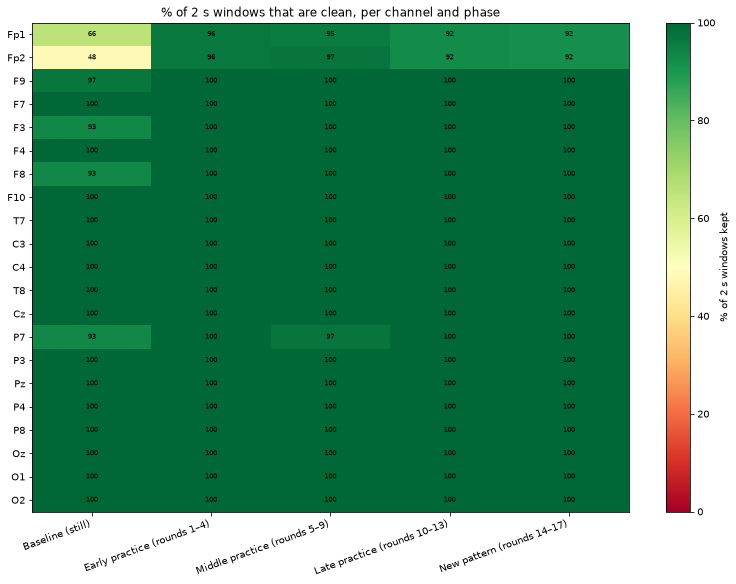

In [4]:
prepared.annotations.append(COUGH[0], COUGH[1] - COUGH[0], "BAD_cough")


def cut(raw, a, b):
    """Times a, b are seconds into the original recording; works for cropped copies too."""
    t0 = raw.first_time - recording.first_time
    return raw.copy().crop(tmin=a - t0, tmax=b - t0, include_tmax=False, verbose="error")


def concat(raws):
    return mne.concatenate_raws([r.copy() for r in raws], verbose="error")


def phase_data(raw):
    """{phase name: Raw} with baseline and each round group (rounds joined end to end)."""
    out = {"Baseline (still)": cut(raw, *BASELINE)}
    for name, idx in GROUPS.items():
        out[name] = concat([cut(raw, *ROUNDS[i]) for i in idx])
    return out


phases = phase_data(prepared)
plot_quality([window_spectra(r) for r in phases.values()], list(phases), "% of 2 s windows that are clean, per channel and phase")

## 3. Band plots: late practice (rounds 10–13) vs new pattern (rounds 14–17)

These two groups are adjacent in time, so they differ mainly in how familiar the pattern was.
The four rounds of each group are joined end to end (dashed lines mark where one round ends and
the next begins); the shaded span in the right column is the cough, excluded from the analysis.

In [5]:
raw_rounds = recording.copy().drop_channels(BAD_CHANNELS)
late_new_labels = ["Late practice (rounds 10–13)", "New pattern (rounds 14–17)"]
round_len = ROUNDS[0, 1] - ROUNDS[0, 0]
edges = [(round_len * (i + 1), "") for i in range(3)]
cough_in_new = (COUGH[0] - ROUNDS[13, 0], min(COUGH[1] - ROUNDS[13, 0], round_len), "cough")
marks = [edges, edges + [cough_in_new]]


def group_rounds(raw, idx, transform=None):
    return concat([transform(cut(raw, *ROUNDS[i])) if transform else cut(raw, *ROUNDS[i]) for i in idx])

### 3.1 Original data (no filtering, original reference)

**Why this plot:** check signal quality before any processing: drift, noisy channels, and movement or blink artifacts that filtering could hide or smear.

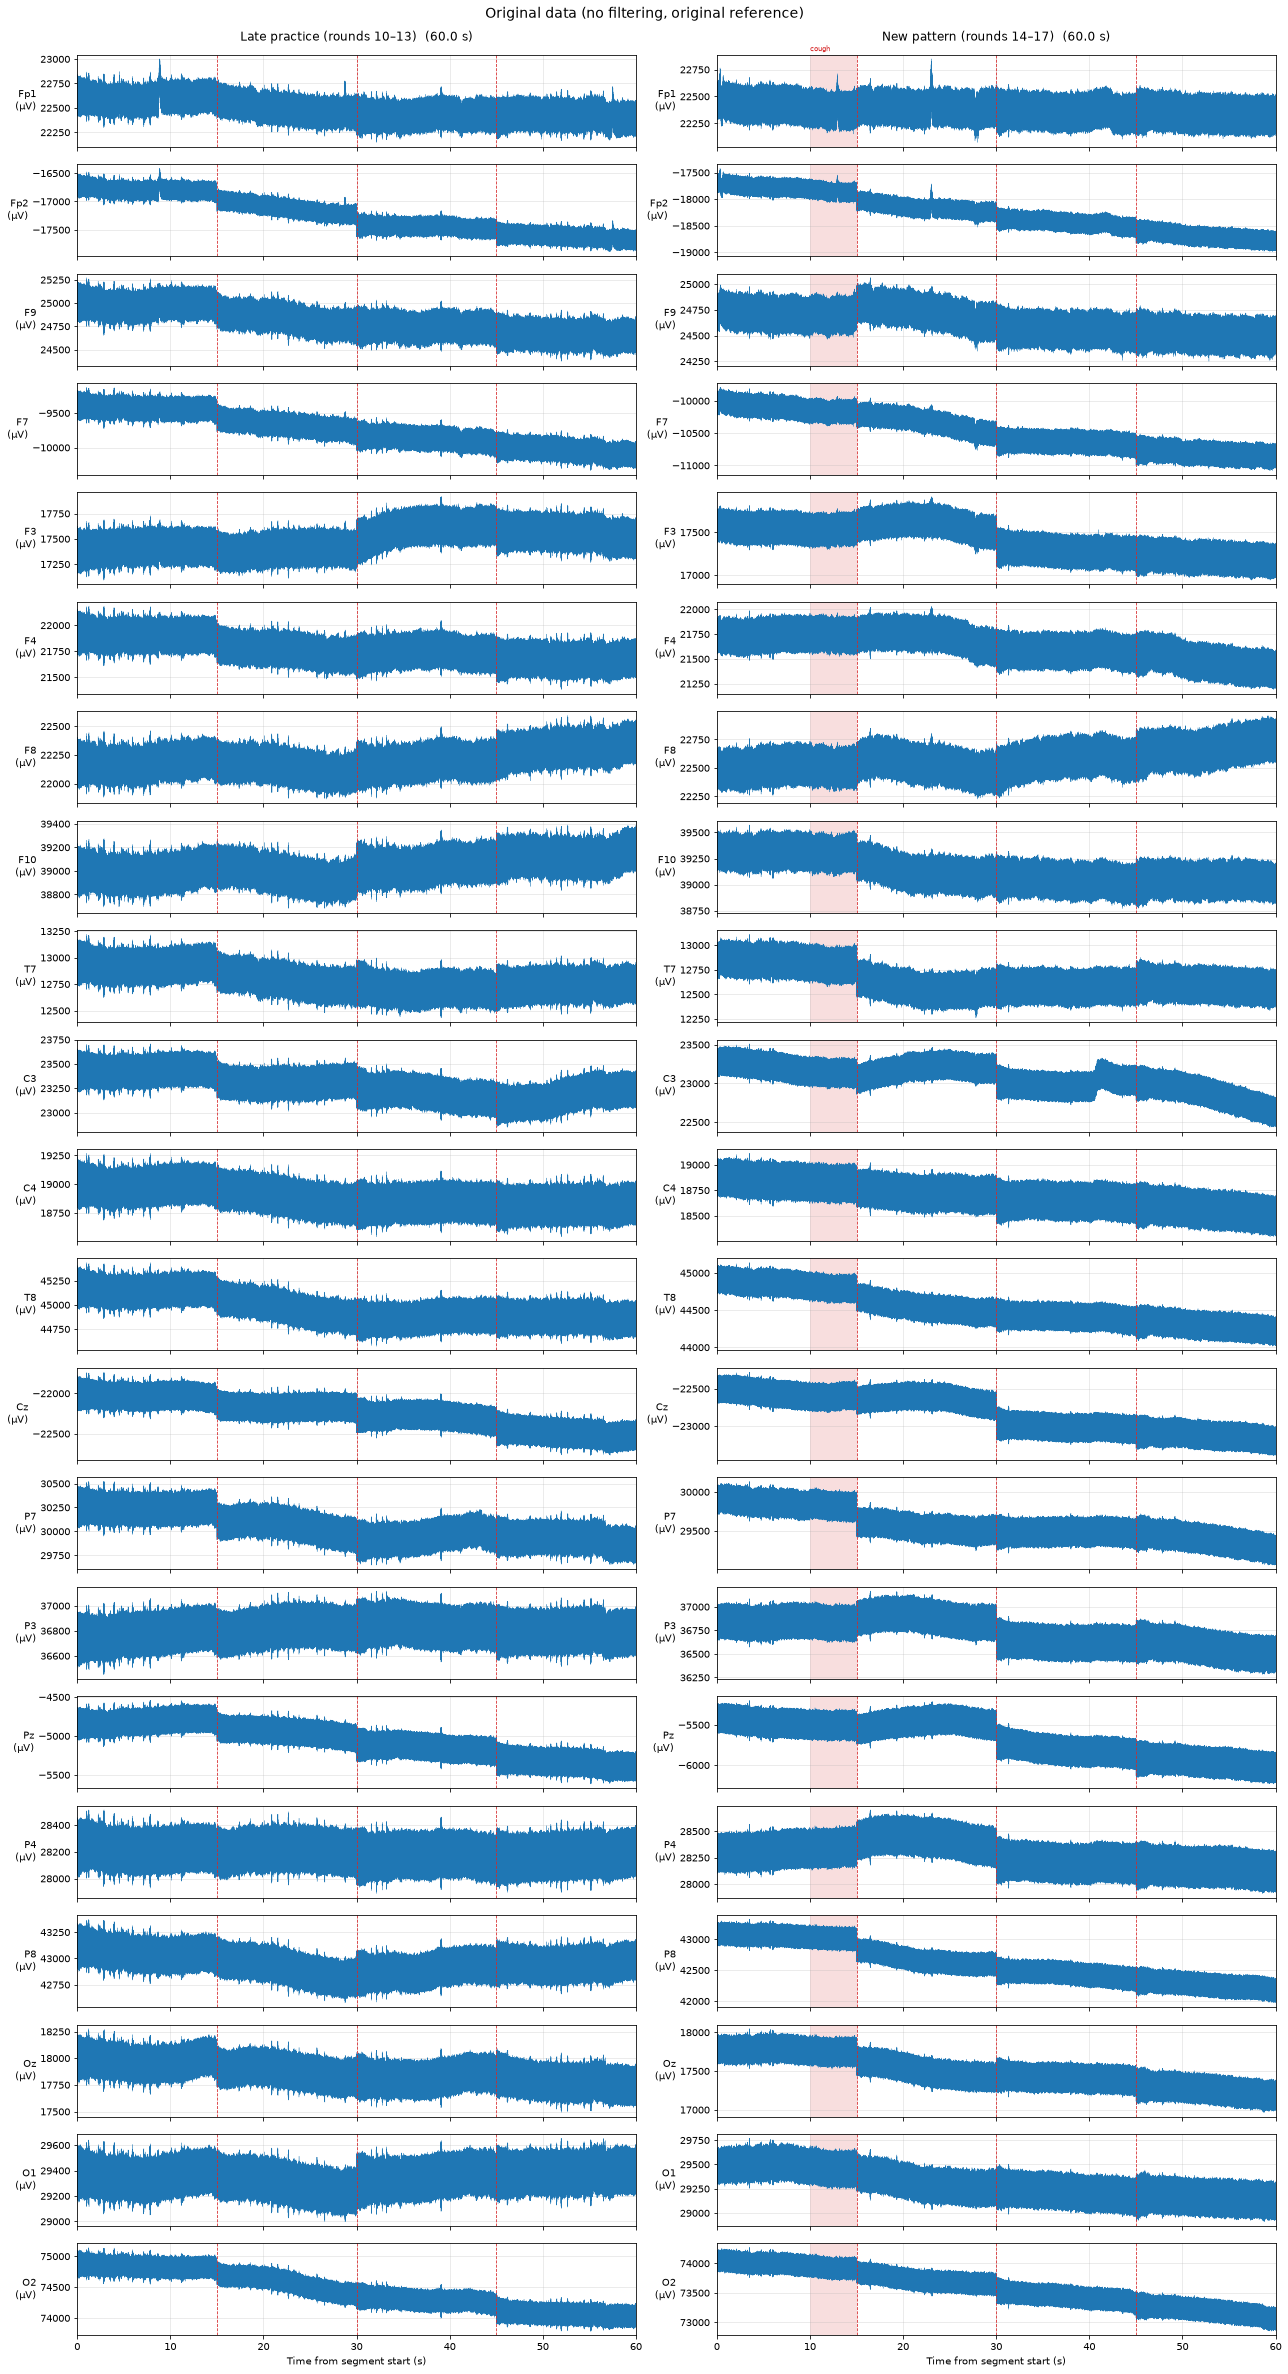

In [6]:
plot_segments([group_rounds(raw_rounds, range(9, 13)), group_rounds(raw_rounds, range(13, 17))], late_new_labels, "Original data (no filtering, original reference)", sharey_rows=False, marks=marks)

### 3.2 Theta band (4–8 Hz)

**Why this plot:** frontal theta (here F3/F4) rises with mental effort, so higher theta for the new pattern than for the practised one would suggest it was more demanding.

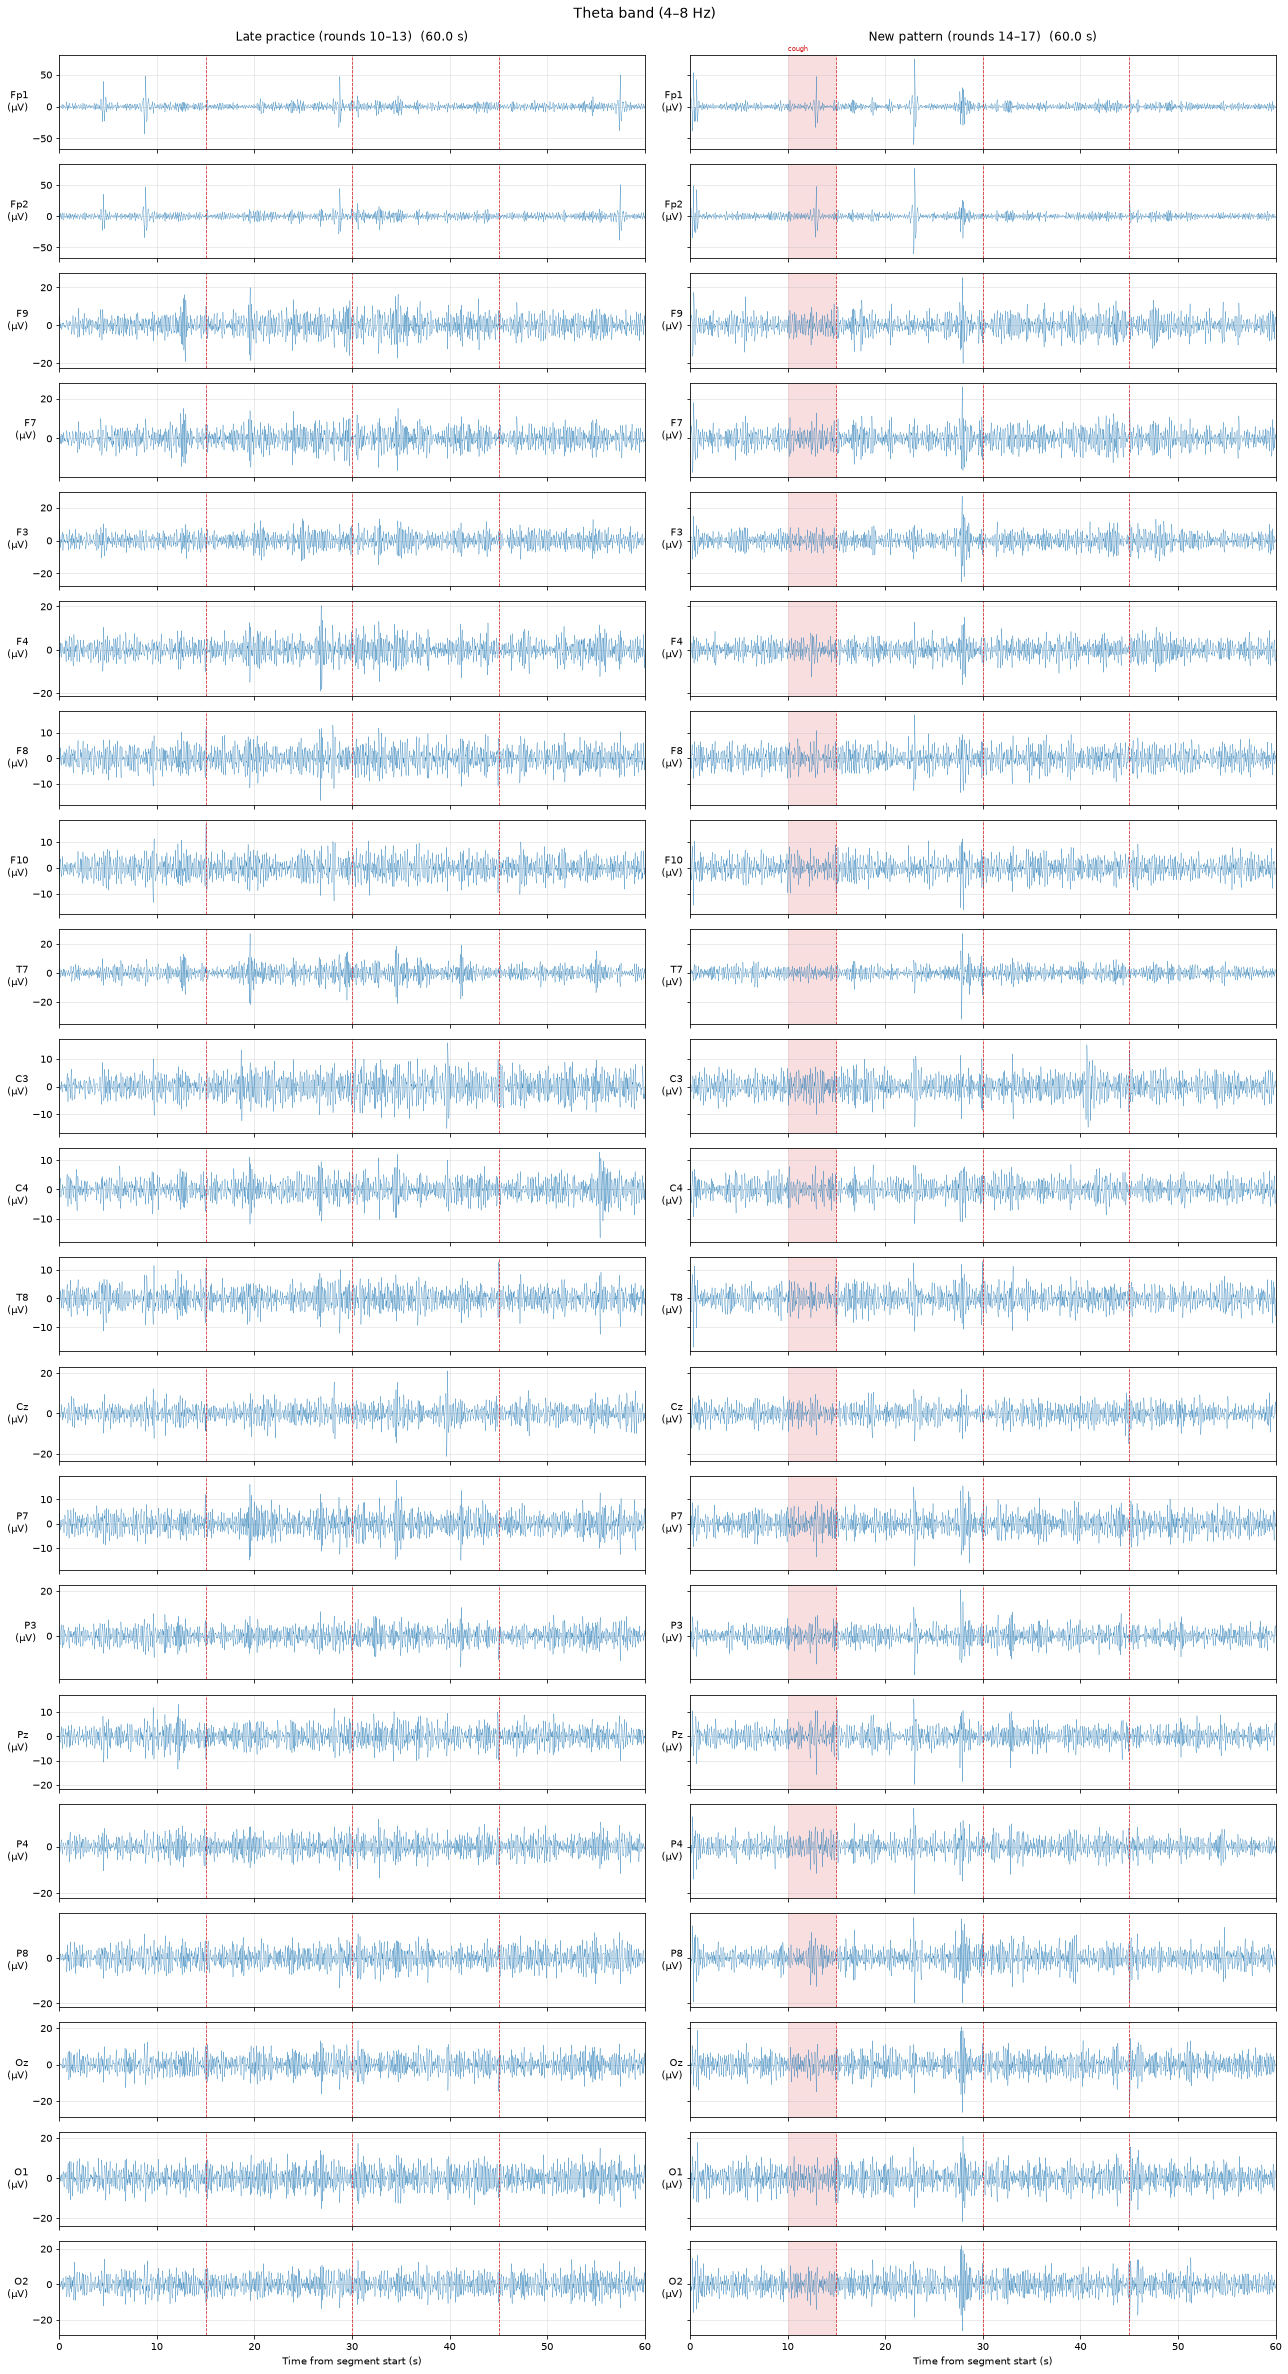

In [7]:
plot_segments([group_rounds(prepared, range(9, 13), lambda s: band_filter(s, 4, 8)), group_rounds(prepared, range(13, 17), lambda s: band_filter(s, 4, 8))], late_new_labels, "Theta band (4–8 Hz)", marks=marks)

### 3.3 Alpha band (8–13 Hz)

**Why this plot:** parietal alpha drops when a task needs more attention, so lower alpha for the new pattern would suggest it demanded more.

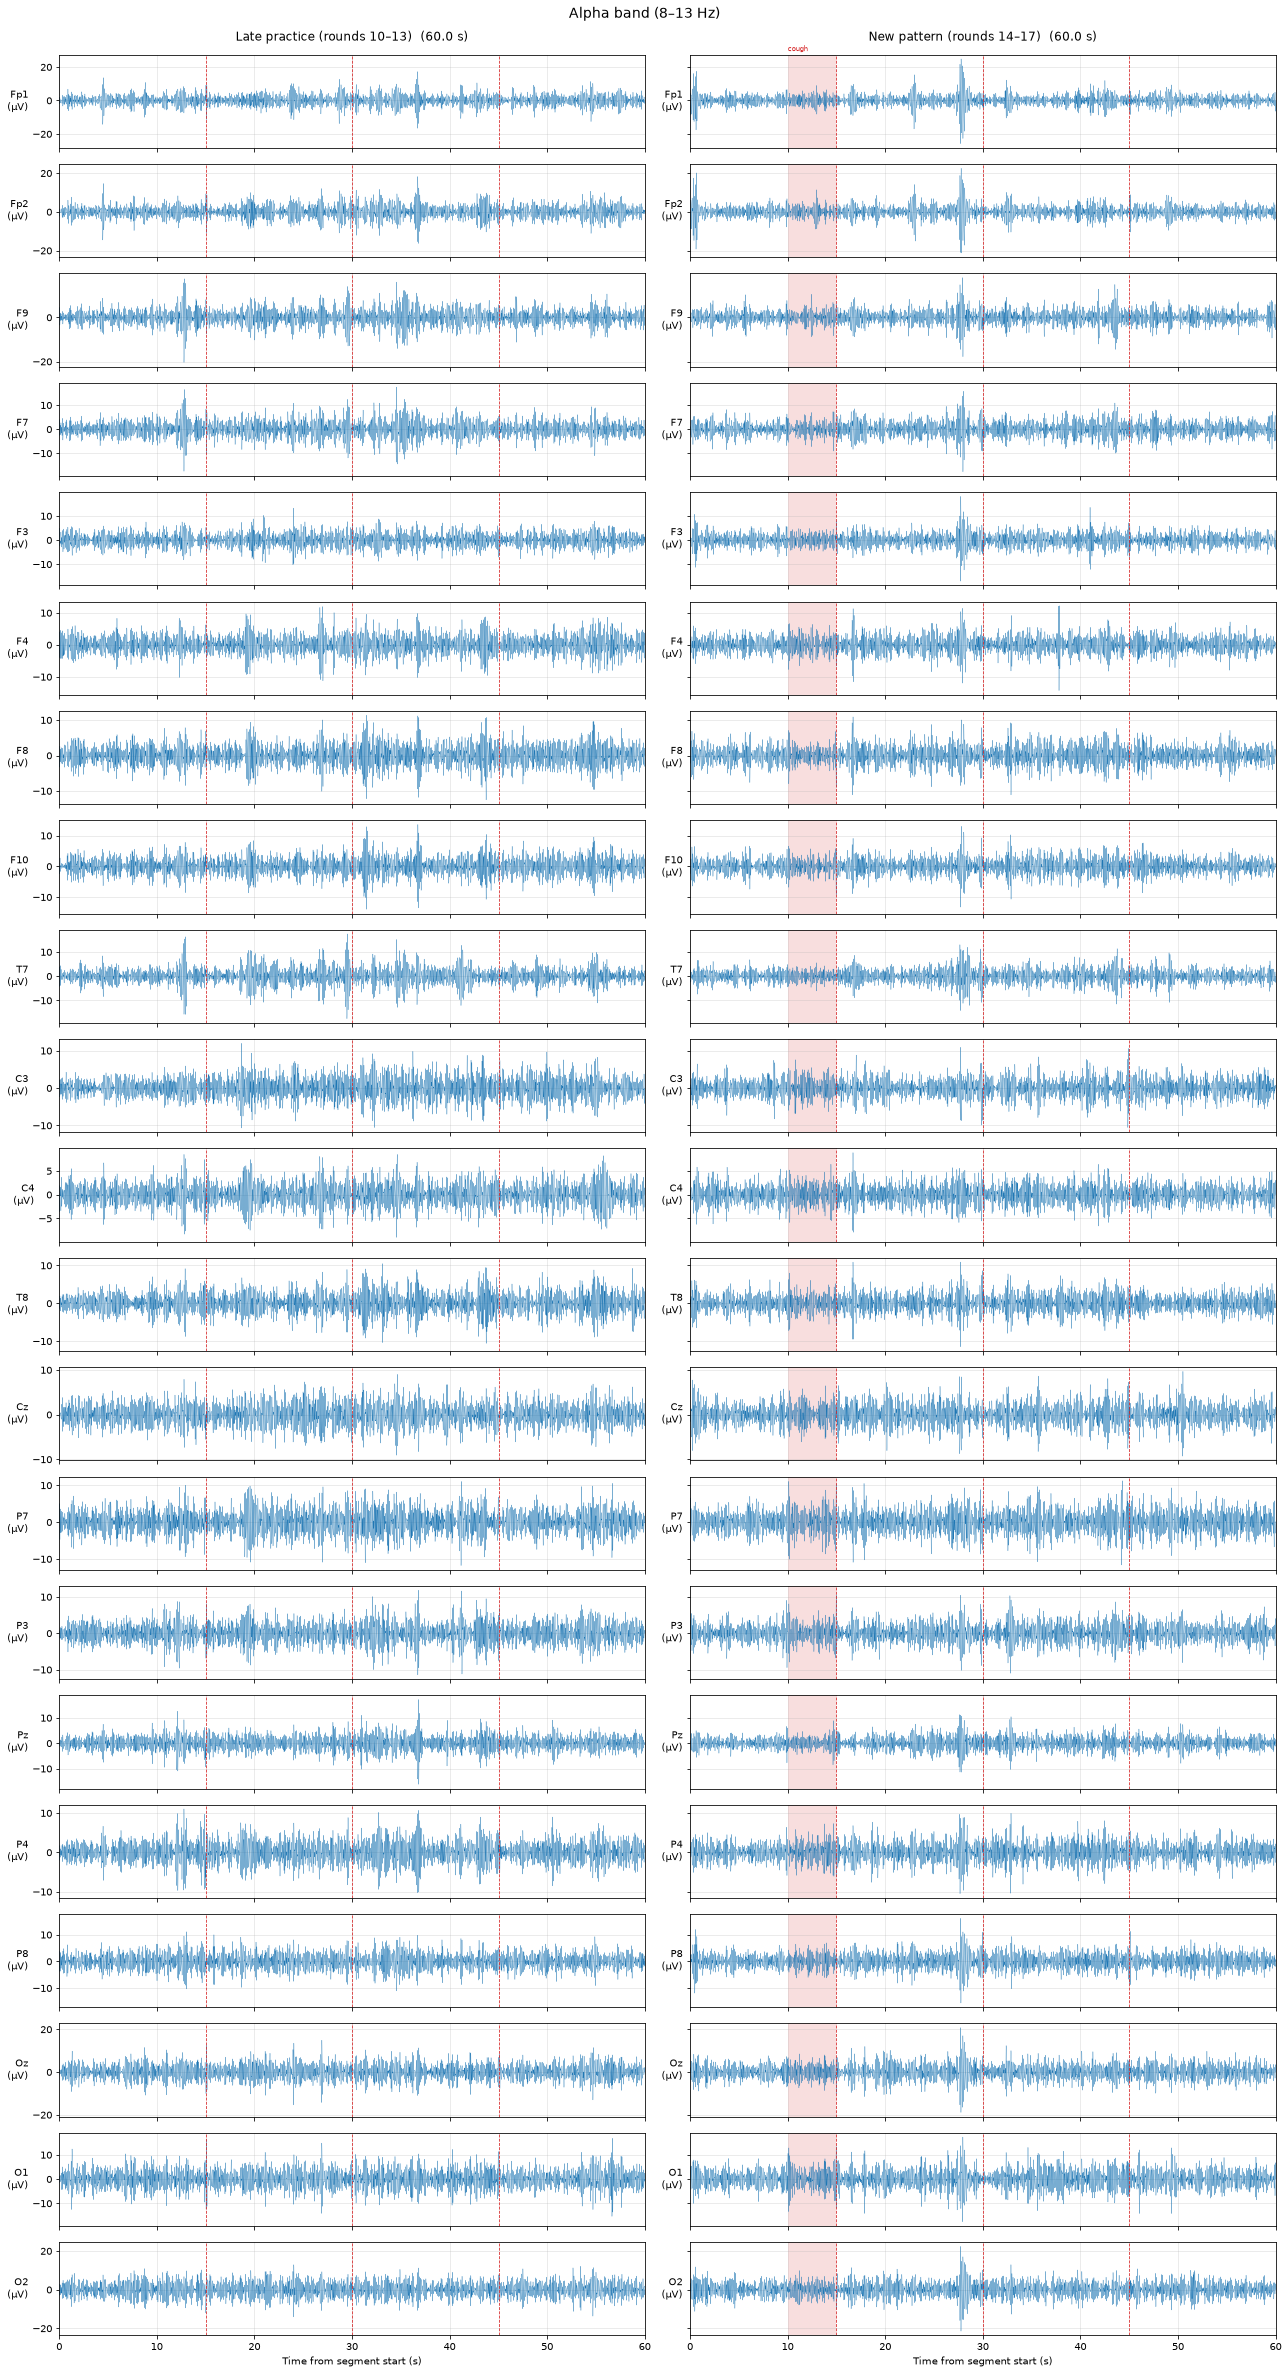

In [8]:
plot_segments([group_rounds(prepared, range(9, 13), lambda s: band_filter(s, 8, 13)), group_rounds(prepared, range(13, 17), lambda s: band_filter(s, 8, 13))], late_new_labels, "Alpha band (8–13 Hz)", marks=marks)

### 3.4 Beta band (13–30 Hz)

**Why this plot:** beta mostly tracks movement (over C4 it drops while the left-hand fingers tap), so it shows whether the tapping itself differed between patterns. It is a confound to watch, not a measure of effort.

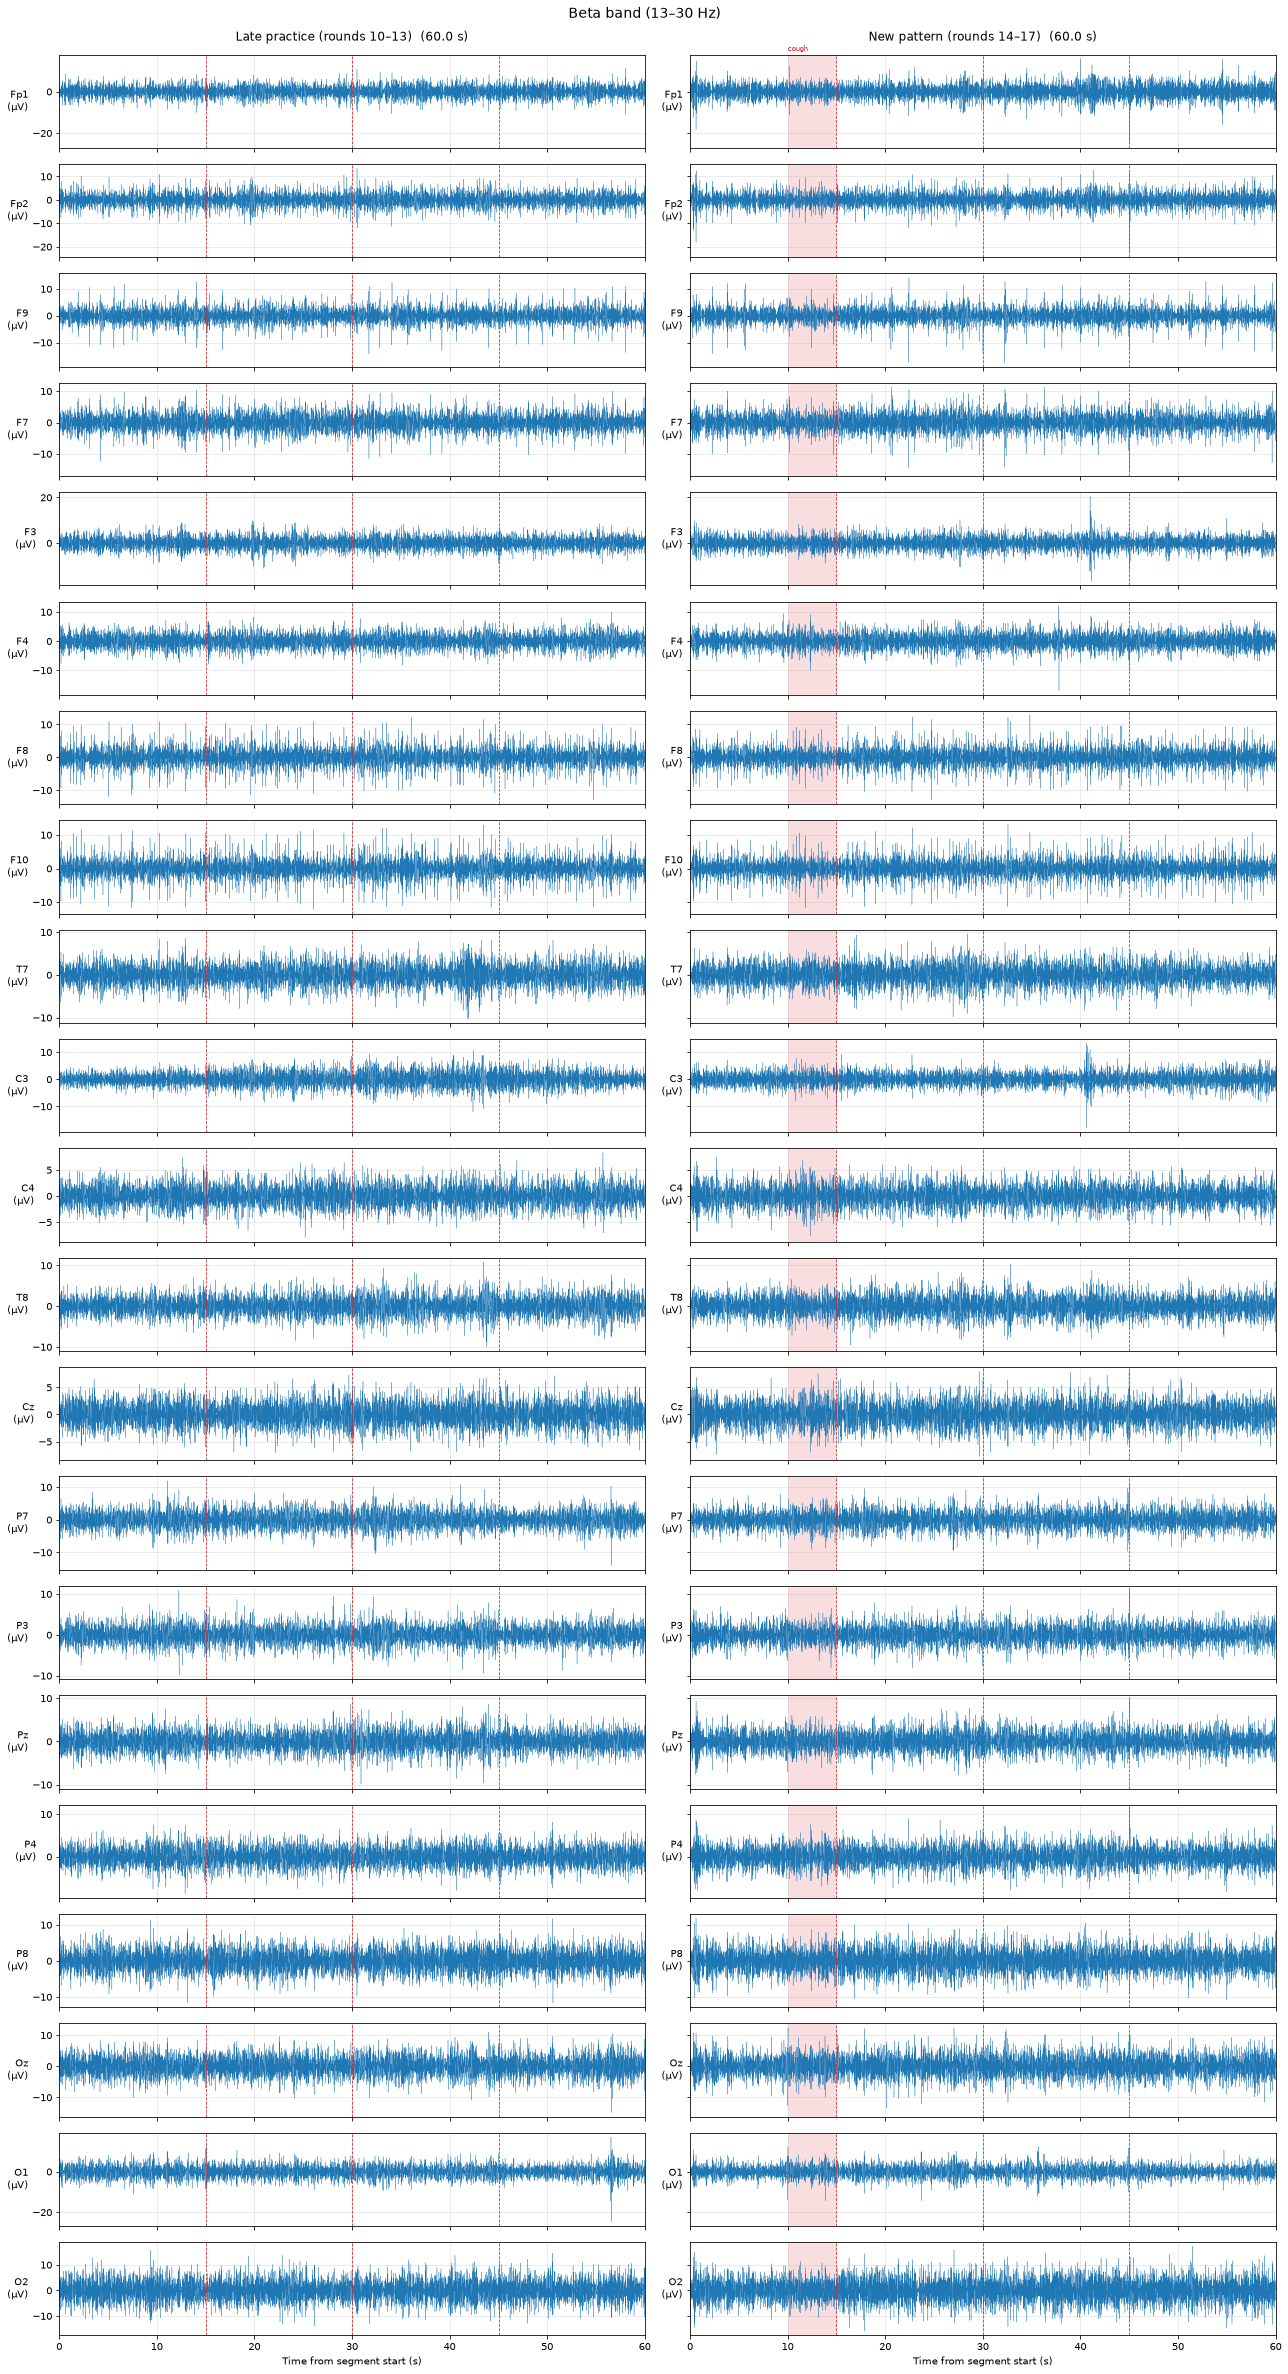

In [9]:
plot_segments([group_rounds(prepared, range(9, 13), lambda s: band_filter(s, 13, 30)), group_rounds(prepared, range(13, 17), lambda s: band_filter(s, 13, 30))], late_new_labels, "Beta band (13–30 Hz)", marks=marks)

### 3.5 Gamma band (30–100 Hz)

**Why this plot:** gamma on the scalp is mostly muscle activity, so it shows whether muscle tension differed between patterns. It is a confound to watch, not a measure of effort.

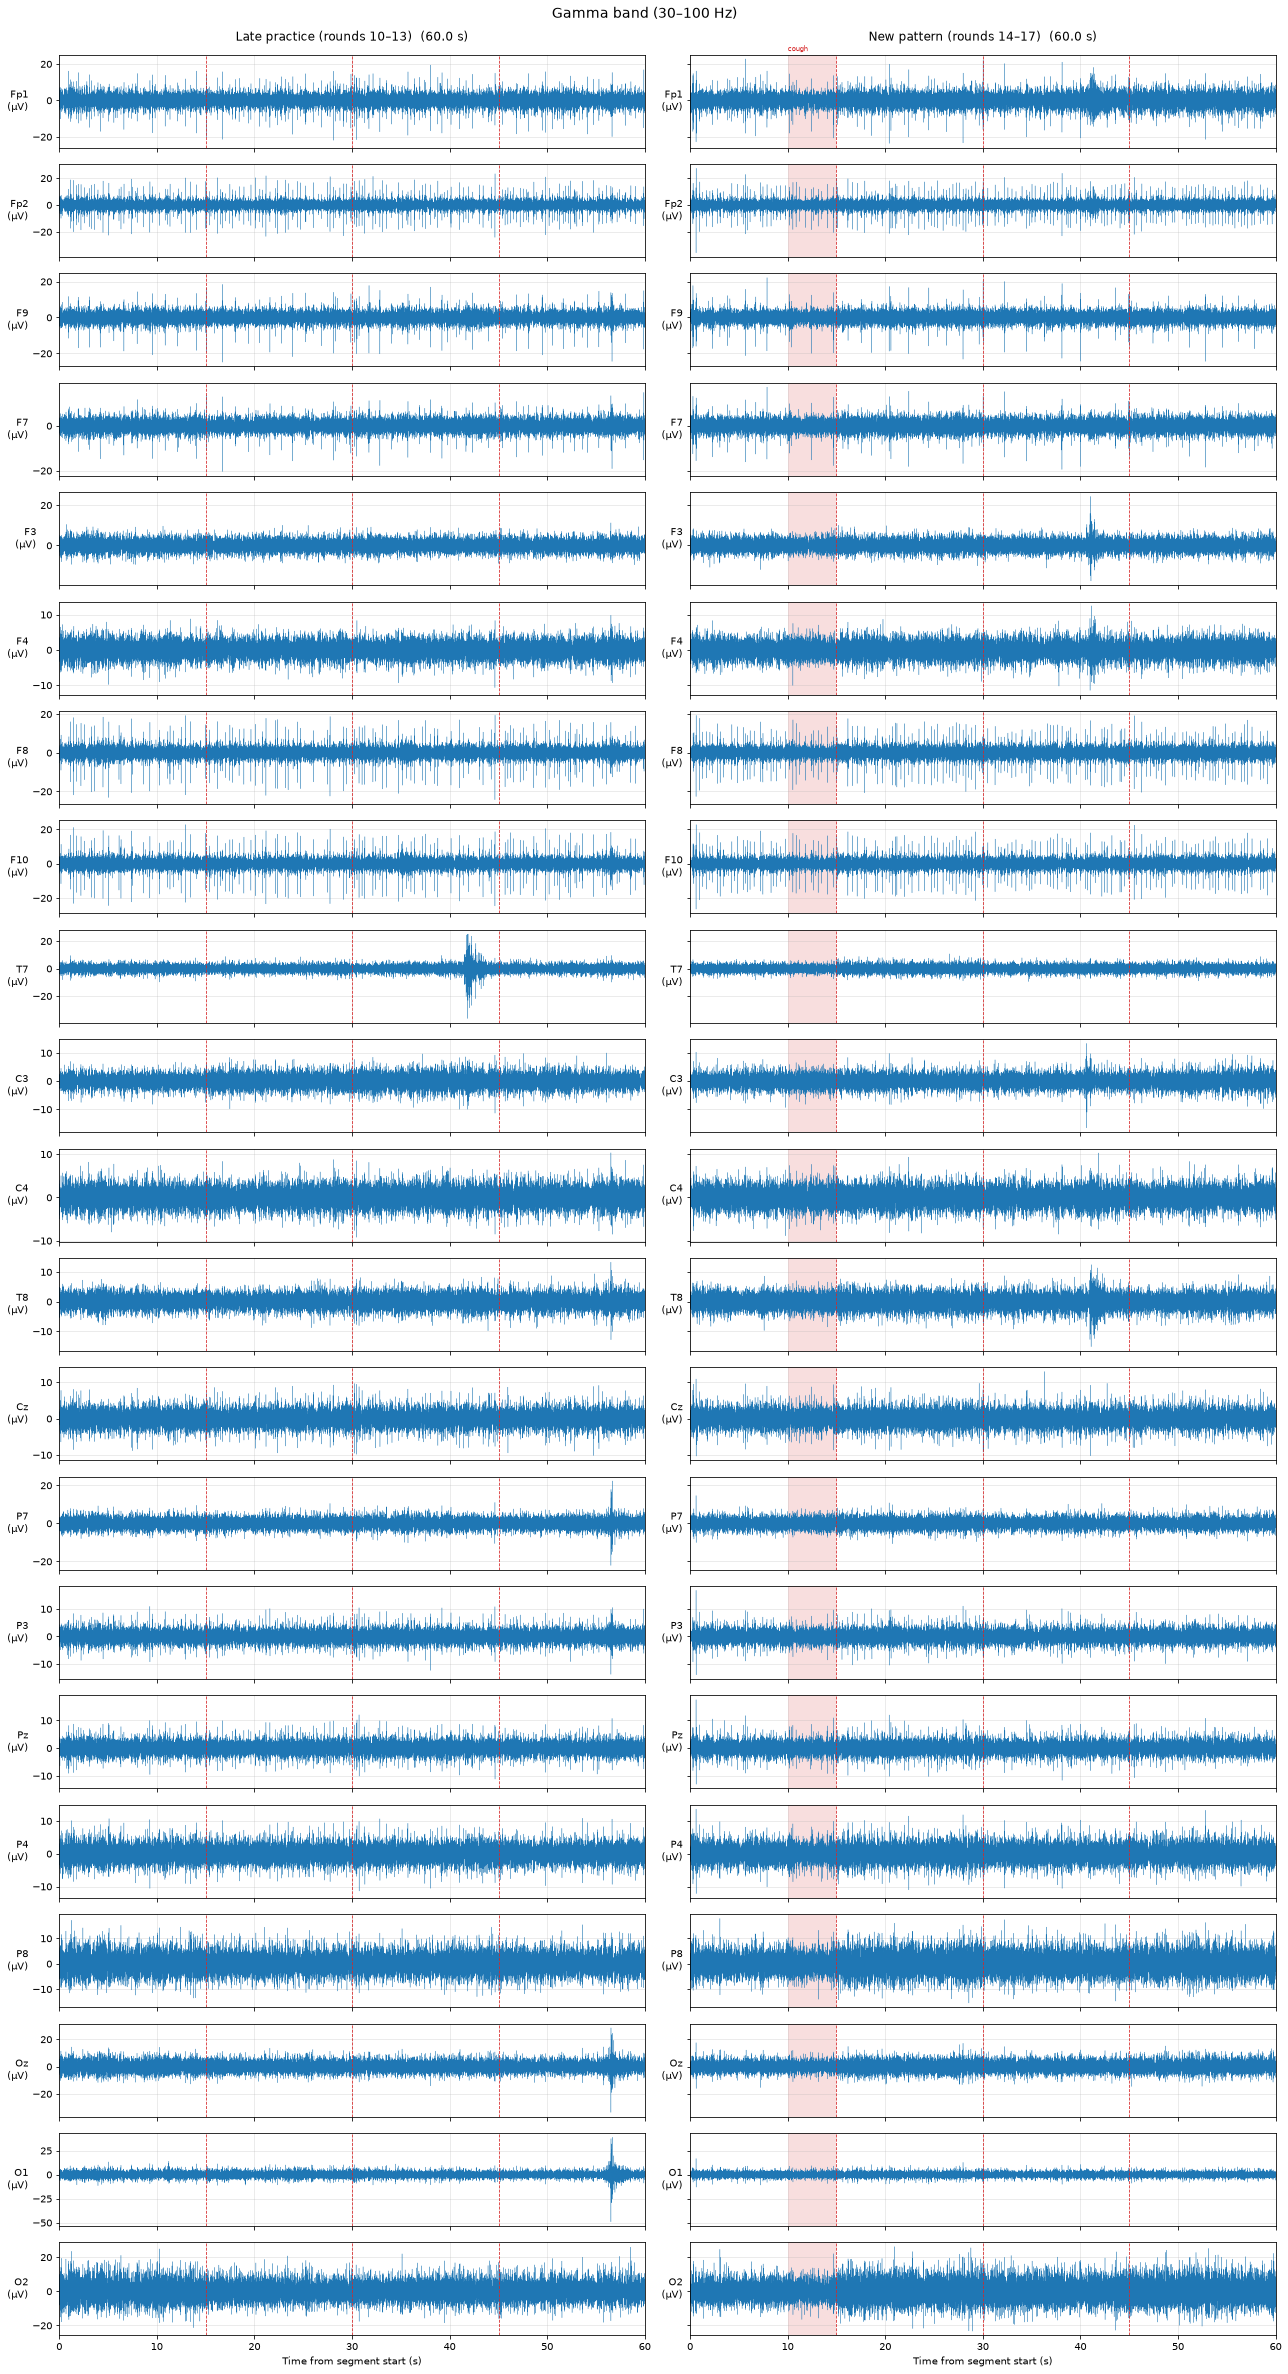

In [10]:
plot_segments([group_rounds(prepared, range(9, 13), lambda s: band_filter(s, 30, 99)), group_rounds(prepared, range(13, 17), lambda s: band_filter(s, 30, 99))], late_new_labels, "Gamma band (30–100 Hz)", marks=marks)

## 4. Frequency decomposition (FFT): late practice vs new pattern

Welch's method (2 s Hann windows, 50% overlap). Relative power is a band's share of 4–40 Hz.

**Why these plots:** the spectra show which frequencies carry the power for the practised and
the new pattern; the bars show across the head whether theta rises and alpha falls for the new one.

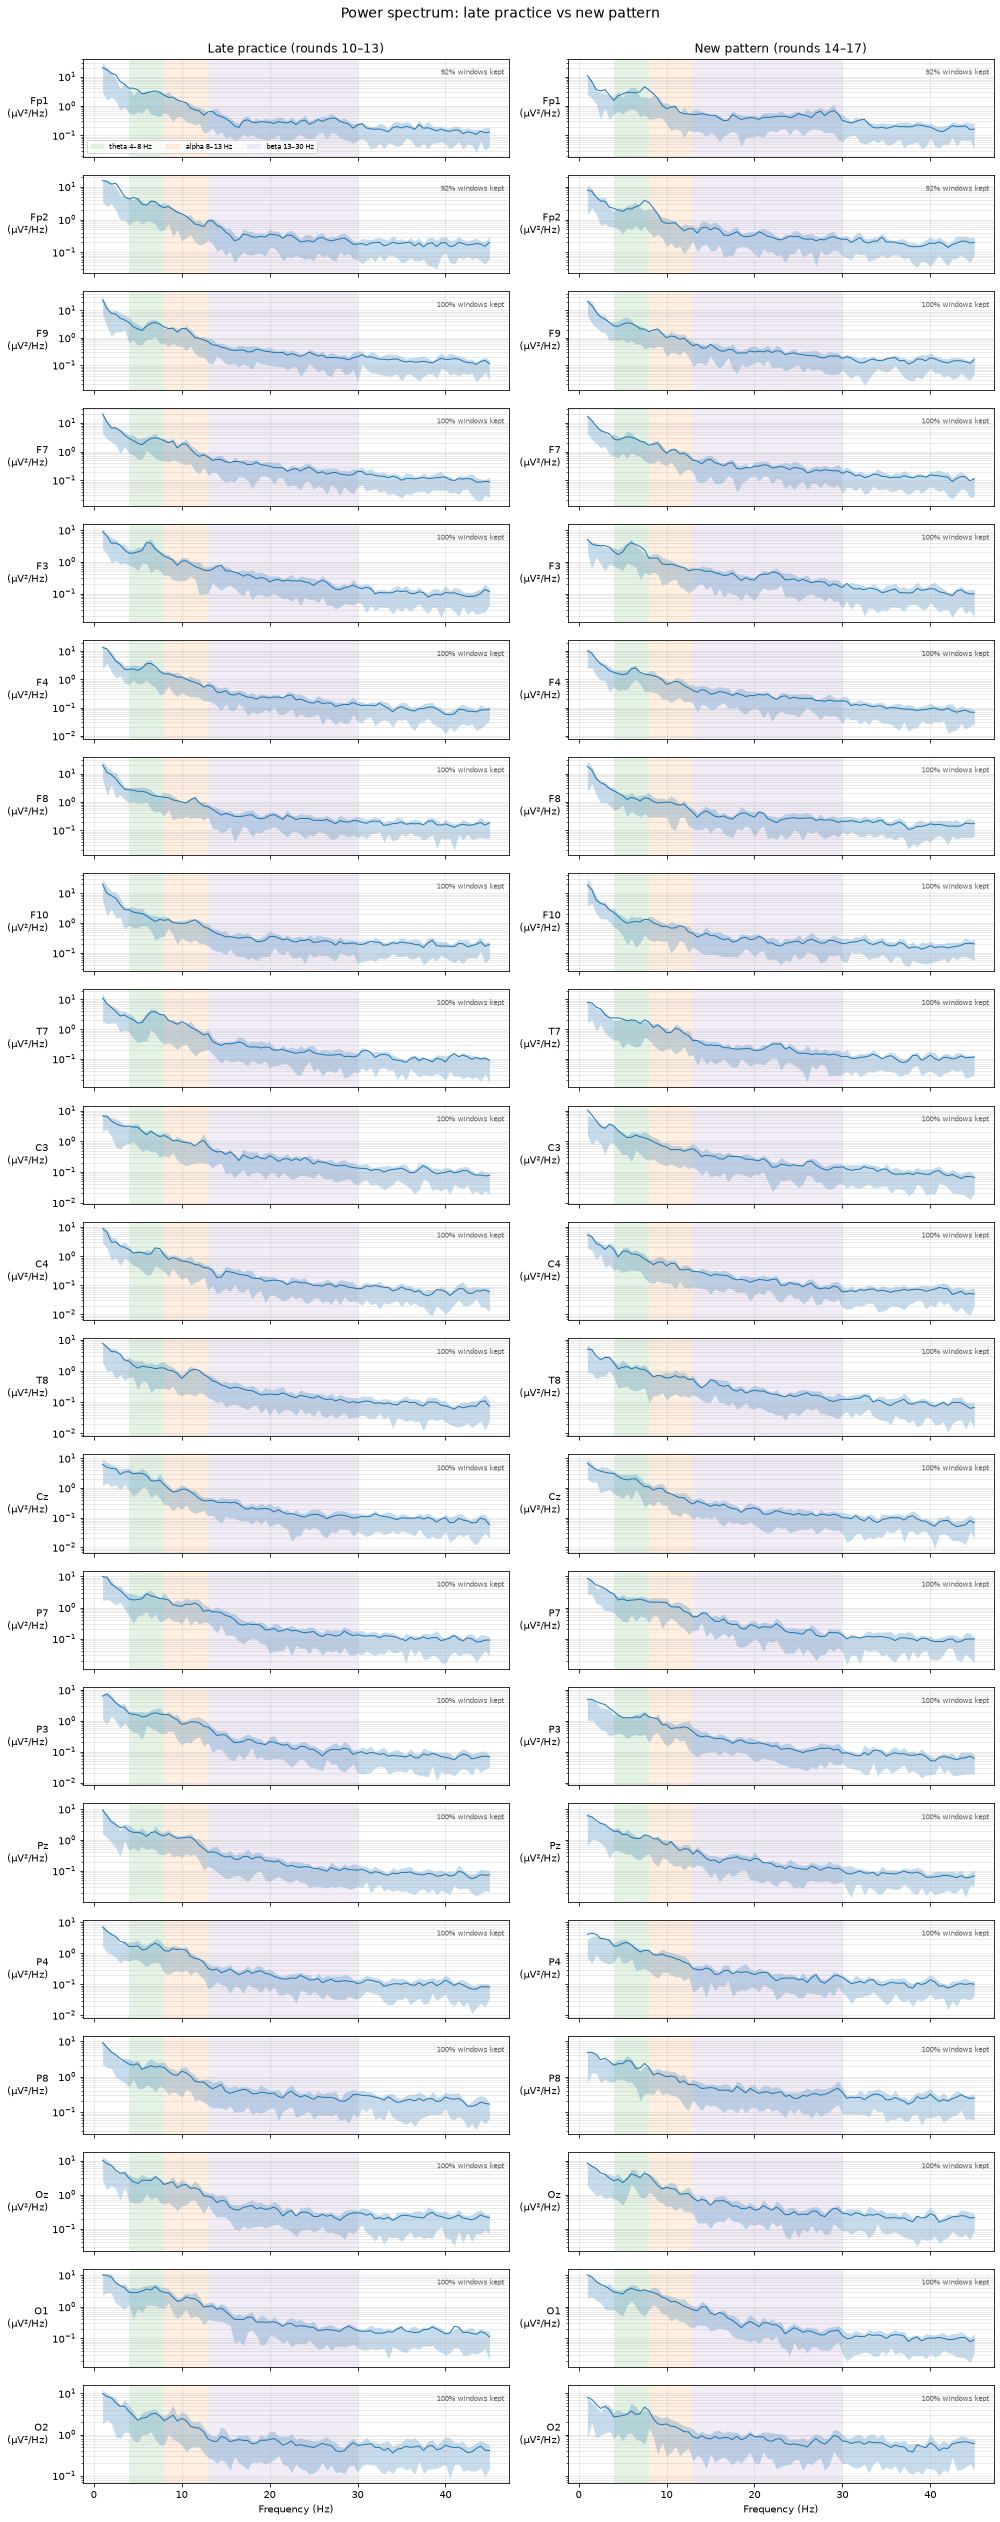

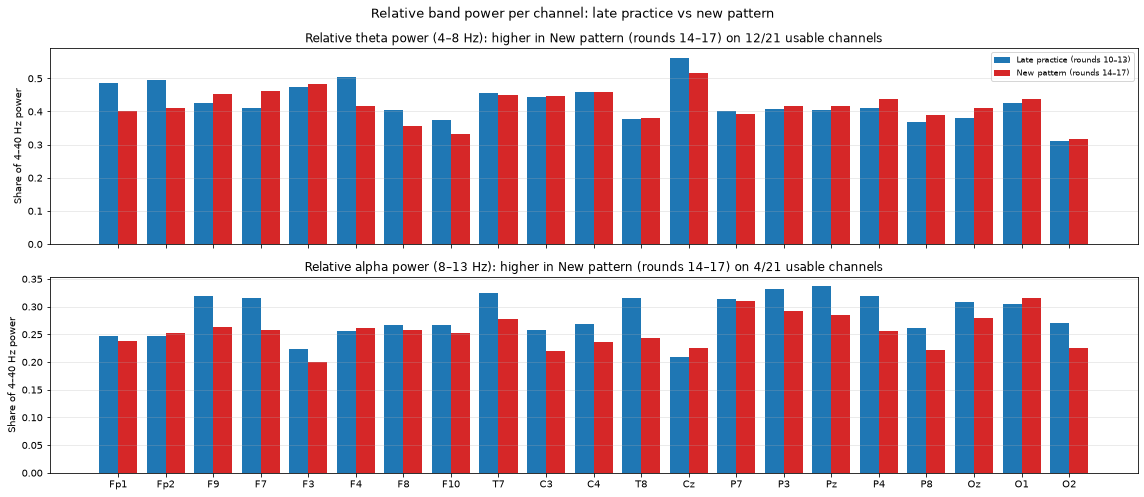

In [11]:
late_new = [phases["Late practice (rounds 10–13)"], phases["New pattern (rounds 14–17)"]]
late_new_spectra = [window_spectra(r) for r in late_new]
plot_spectra(late_new_spectra, late_new_labels, "Power spectrum: late practice vs new pattern")
plot_relative_bars(late_new_spectra, late_new_labels, "Relative band power per channel: late practice vs new pattern")

## 5. Cleaned analysis: ICA + theta/alpha above the 1/f background

One ICA is fitted on the whole session from the start of the baseline to the end of round 17
(rests included, cough excluded); ICLabel removes components confidently (probability ≥ 0.7)
classified as eye, muscle, heart, line noise or channel noise. FOOOF then measures theta
(F3+F4) and alpha (Pz) as power above the 1/f background, in dB.

ICA: 3 of 20 components removed: IC00 eye blink (0.99), IC01 eye blink (1.00), IC14 eye blink (0.85)


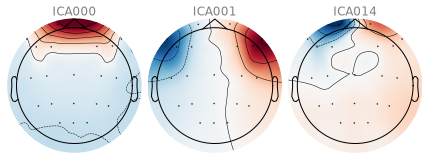

In [12]:
session_span = prepared.copy().crop(tmin=BASELINE[0], tmax=min(ROUNDS[-1, 1] + 5, prepared.times[-1]), verbose="error")
(clean_span,), ica_report, ica = ica_clean([session_span])
print(f"ICA: {int(ica_report.removed.sum())} of {len(ica_report)} components removed: "
      + ", ".join(f"{r.component} {r.label} ({r.probability:.2f})" for r in ica_report[ica_report.removed].itertuples()))
ica.plot_components(picks=ica.exclude, title="Components removed by ICLabel", show=False)
plt.show()
clean_phases = phase_data(clean_span)

### 5.1 Round by round

Theta above 1/f at F3+F4, alpha above 1/f at Pz and the 1/f exponent at F3+F4 for every round
(15 s each), with the still baseline as a dashed line. The trend over the 13 practice rounds is
summarized with a Spearman correlation (descriptive).

**Why this plot:** learning should show as a gradual change across the practice rounds, and the
new pattern as a jump at round 14, so this shows the shape of both.

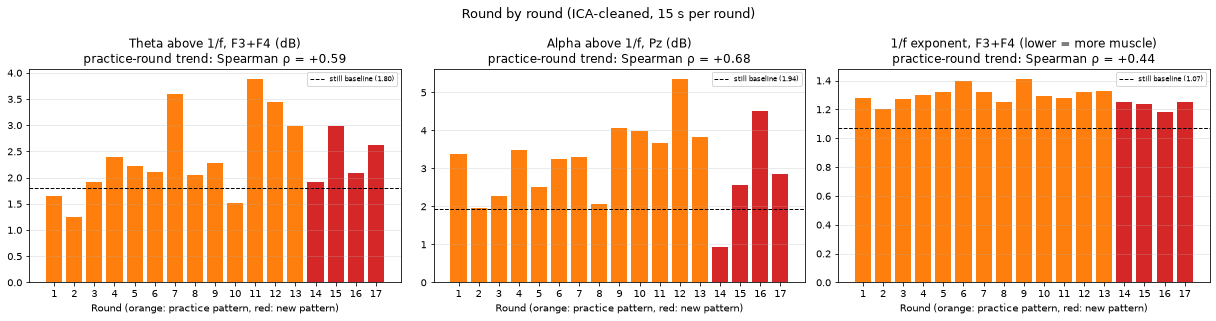

,round,pattern,theta_F3+F4_dB,alpha_Pz_dB,exponent_F3+F4,windows_clean_%
0,1,practice,1.64,3.37,1.28,100
1,2,practice,1.25,1.96,1.20,100
2,3,practice,1.92,2.28,1.27,100
3,4,practice,2.40,3.49,1.30,100
4,5,practice,2.23,2.50,1.32,100
5,6,practice,2.11,3.26,1.40,100
6,7,practice,3.60,3.31,1.32,100
7,8,practice,2.05,2.05,1.25,100
8,9,practice,2.27,4.05,1.41,100
9,10,practice,1.52,3.99,1.29,100


,theta_F3+F4_dB,alpha_Pz_dB,exponent_F3+F4
group,,,
Early practice (rounds 1–4),1.80,2.78,1.26
Middle practice (rounds 5–9),2.45,3.03,1.34
Late practice (rounds 10–13),2.96,4.21,1.31
New pattern (rounds 14–17),2.40,2.71,1.23


In [13]:
rows = []
for i, (a, b) in enumerate(ROUNDS):
    sp = roi_spectrum(window_spectra(cut(clean_span, a, b)), THETA_CHANNELS)
    m = periodic_metrics(sp, THETA_SITE, ALPHA_SITE)
    rows.append({"round": i + 1, "pattern": PATTERN[i], "theta_F3+F4_dB": m["theta_db"], "alpha_Pz_dB": m["alpha_db"],
                 "exponent_F3+F4": m[f"exponent_{THETA_SITE}"], "windows_clean_%": round(100 * sp[3][-1])})
per_round = pd.DataFrame(rows).round(2)
base = periodic_metrics(roi_spectrum(window_spectra(clean_phases["Baseline (still)"]), THETA_CHANNELS), THETA_SITE, ALPHA_SITE)
base_vals = {"theta_F3+F4_dB": base["theta_db"], "alpha_Pz_dB": base["alpha_db"], "exponent_F3+F4": base[f"exponent_{THETA_SITE}"]}

practice = per_round[per_round.pattern == "practice"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col, title in zip(axes, ["theta_F3+F4_dB", "alpha_Pz_dB", "exponent_F3+F4"],
                          ["Theta above 1/f, F3+F4 (dB)", "Alpha above 1/f, Pz (dB)", "1/f exponent, F3+F4 (lower = more muscle)"]):
    rho = spearmanr(practice["round"], practice[col]).correlation
    ax.bar(per_round["round"], per_round[col], color=["C1" if p == "practice" else "C3" for p in per_round.pattern])
    ax.axhline(base_vals[col], color="k", ls="--", lw=1, label=f"still baseline ({base_vals[col]:.2f})")
    ax.set_xticks(per_round["round"])
    ax.set_xlabel("Round (orange: practice pattern, red: new pattern)")
    ax.set_title(f"{title}\npractice-round trend: Spearman ρ = {rho:+.2f}")
    ax.legend(fontsize=7)
    ax.grid(axis="y", alpha=0.3)
fig.suptitle("Round by round (ICA-cleaned, 15 s per round)", fontsize=13)
fig.tight_layout()
plt.show()

group_means = per_round.assign(group=[next(g for g, idx in GROUPS.items() if r - 1 in idx) for r in per_round["round"]]) \
    .groupby("group", sort=False)[["theta_F3+F4_dB", "alpha_Pz_dB", "exponent_F3+F4"]].mean().round(2)
display(per_round)
display(group_means)

### 5.2 Hypothesis 1, learning: early practice (rounds 1–4) vs late practice (rounds 10–13)

**Why this plot:** if the practice pattern became easier, theta should be lower and alpha
higher in late practice; this compares every non-overlapping 2 s window of the two groups.

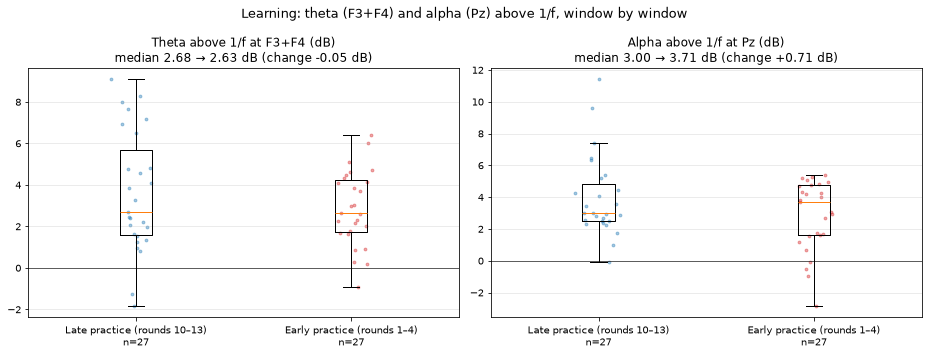

,Late practice (rounds 10–13),Early practice (rounds 1–4),change_dB,descriptive_p_higher,descriptive_p_lower,n
measure,,,,,,
Theta above 1/f at F3+F4 (dB),2.68,2.63,-0.05,0.75,0.26,27 / 27
Alpha above 1/f at Pz (dB),3.00,3.71,0.71,0.80,0.21,27 / 27


In [14]:
learn_labels = ["Late practice (rounds 10–13)", "Early practice (rounds 1–4)"]   # easier first, harder second
learn = [roi_spectrum(window_spectra(clean_phases[k], overlap=0.0), THETA_CHANNELS) for k in learn_labels]
periodic_workload_comparison(learn, learn_labels, "Learning: theta (F3+F4) and alpha (Pz) above 1/f, window by window",
                             theta_ch=THETA_SITE, alpha_ch=ALPHA_SITE)

### 5.3 Hypothesis 2, new pattern: late practice (rounds 10–13) vs new pattern (rounds 14–17)

**Why these plots:** the two groups are back to back in time, so a theta increase for the new
pattern would point to effort rather than fatigue; the spectra show whether it is a real theta
peak above the 1/f background.

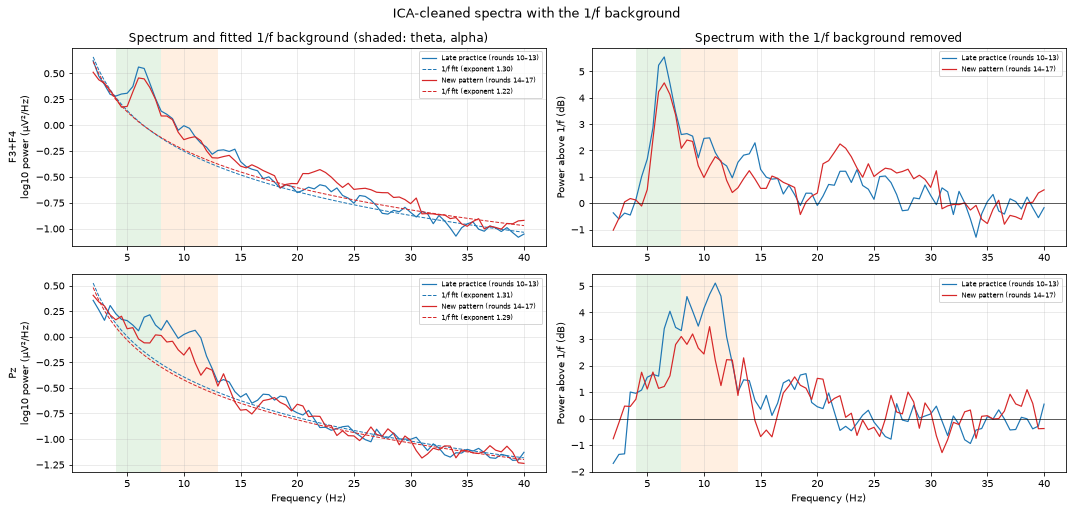

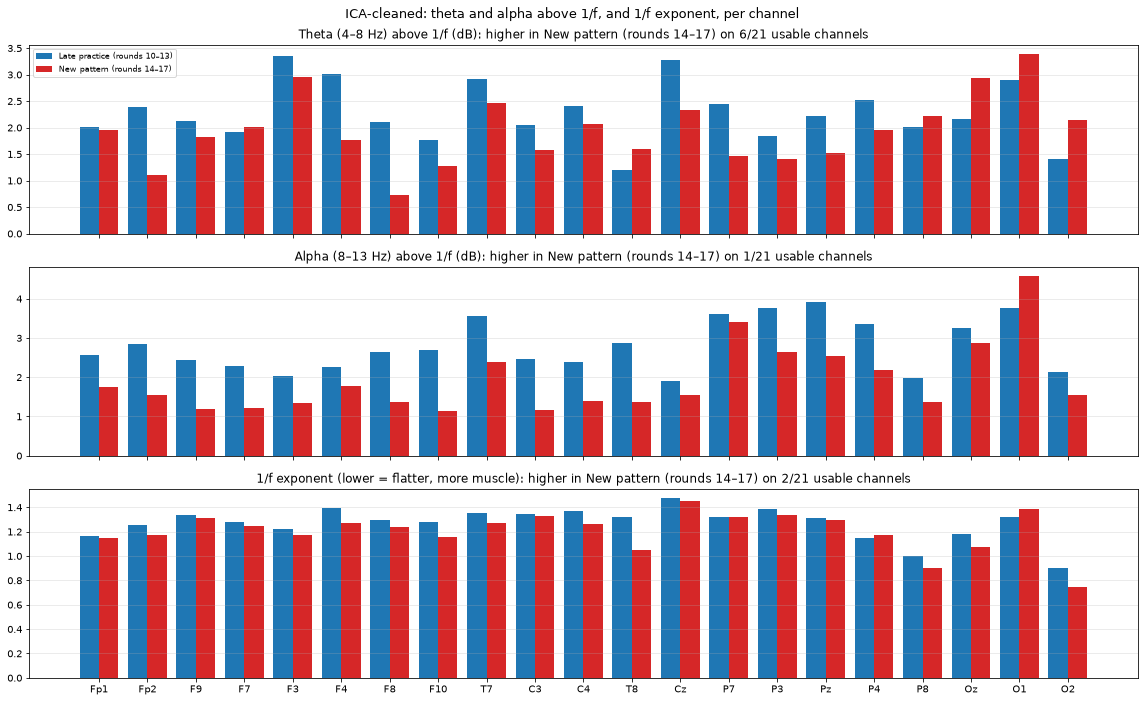

Late practice (rounds 10–13): theta F3+F4 +3.06 dB, alpha Pz +3.92 dB (averaged spectrum)
New pattern (rounds 14–17): theta F3+F4 +2.40 dB, alpha Pz +2.55 dB (averaged spectrum)


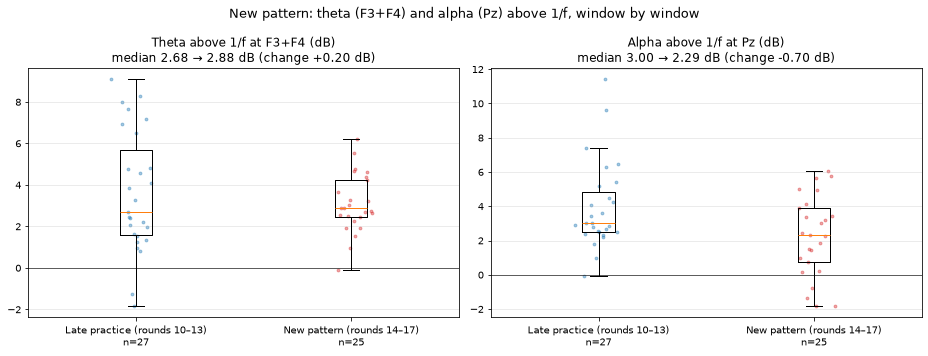

,Late practice (rounds 10–13),New pattern (rounds 14–17),change_dB,descriptive_p_higher,descriptive_p_lower,n
measure,,,,,,
Theta above 1/f at F3+F4 (dB),2.68,2.88,0.2,0.54,0.470,27 / 25
Alpha above 1/f at Pz (dB),3.00,2.29,-0.7,0.98,0.021,27 / 25


In [15]:
novel_labels = ["Late practice (rounds 10–13)", "New pattern (rounds 14–17)"]
novel = [roi_spectrum(window_spectra(clean_phases[k]), THETA_CHANNELS) for k in novel_labels]
plot_fooof_fits(novel, novel_labels, "ICA-cleaned spectra with the 1/f background", channels=(THETA_SITE, ALPHA_SITE))
plot_periodic_bars([(p[:, :-1], f, c[:-1], k[:-1]) for p, f, c, k in novel], novel_labels,
                   "ICA-cleaned: theta and alpha above 1/f, and 1/f exponent, per channel")
for label, sp in zip(novel_labels, novel):
    m = periodic_metrics(sp, THETA_SITE, ALPHA_SITE)
    print(f"{label}: theta F3+F4 {m['theta_db']:+.2f} dB, alpha Pz {m['alpha_db']:+.2f} dB (averaged spectrum)")
novel_nonoverlap = [roi_spectrum(window_spectra(clean_phases[k], overlap=0.0), THETA_CHANNELS) for k in novel_labels]
periodic_workload_comparison(novel_nonoverlap, novel_labels, "New pattern: theta (F3+F4) and alpha (Pz) above 1/f, window by window",
                             theta_ch=THETA_SITE, alpha_ch=ALPHA_SITE)

## 6. Results: do the data support the hypotheses?

**Partly. Parietal alpha behaves as predicted for the new pattern: it drops on every measure
when the unfamiliar sequence starts, even though those rounds come latest in the session.
Frontal theta does not follow either hypothesis: it rises over the practice rounds and doesn't
increase for the new pattern.**

| Measure (ICA-cleaned, above 1/f) | Early practice (1–4) | Late practice (10–13) | New pattern (14–17) | Still baseline |
|---|---|---|---|---|
| Theta at F3+F4, mean of rounds | 1.80 dB | 2.96 dB | 2.40 dB | 1.80 dB |
| Alpha at Pz, mean of rounds | 2.78 dB | 4.21 dB | 2.71 dB | 1.94 dB |
| 1/f exponent at F3+F4, mean of rounds | 1.26 | 1.31 | 1.23 | 1.07 |

**Hypothesis 1, learning (early vs late practice):**
- **Theta rose instead of falling** over the 13 practice rounds (Spearman ρ = +0.59; 1.80 → 2.96 dB
  between the first and last four rounds). In the window-by-window comparison it is flat (+0.05 dB).
- **Alpha rose across practice rounds** (ρ = +0.68; 2.78 → 4.21 dB), as predicted for a task getting
  easier. But it also fits growing fatigue or relaxation, and the window medians point the other way
  (3.71 → 3.00 dB). So learning isn't supported on its own.

**Hypothesis 2, new pattern (late practice vs new pattern):**
- **Alpha dropped on every measure:** −1.5 dB (mean of rounds), −1.4 dB (averaged spectrum,
  3.92 → 2.55 dB), −0.7 dB (window median, descriptive p = 0.02). Round 14, the first with the new
  pattern, has the lowest alpha of the whole task (0.93 dB). Fatigue would have pushed alpha
  *up* at this point, so this drop points to the new pattern demanding more attention.
- **Theta did not rise:** −0.6 dB (mean of rounds), −0.7 dB (averaged spectrum, 3.06 → 2.40 dB), +0.2 dB (window median,
  descriptive p = 0.54).
- **The 1/f exponent is slightly lower for the new pattern** (1.31 → 1.23), suggesting a bit more
  muscle tension, which FOOOF separates from the alpha peak.

How to read this:
- **The clearest effort signal in this session is alpha, not theta.** It falls when the task
  becomes unfamiliar, the pattern the hypothesis predicts. Frontal theta seems to track time on
  task here, as it did in the earlier, coarser analysis.
- **Fz couldn't be used** (saturated electrode). Frontal-midline theta is strongest at Fz, so F3+F4
  may simply be too far off-centre to pick it up.
- **Each round is only 15 s** (about 7 non-overlapping windows), so single-round values are noisy;
  the group means over four rounds are more reliable than any one bar.
- **Clock alignment:** the round schedule was fitted to the data (eye activity drops during every
  round and recovers in every rest; motor beta agrees). The notes' clock is 16.6 s ahead of the
  recording. The noted cough time (372 s on the recording clock) is about 5 s before the largest
  burst (377 s), so 371–380 s is excluded.

**Next steps:** tapping speed and accuracy per round would confirm when learning happened, and a
working Fz electrode would test frontal-midline theta directly.

## 7. Theta power check

### 7.1 Definition

**Theta power** at a channel is the total power of the EEG between 4 and 8 Hz:

$$\theta = \int_{4\,\mathrm{Hz}}^{8\,\mathrm{Hz}} P(f)\,df \;\approx\; \sum_{4 \le f_k < 8} P(f_k)\,\Delta f \qquad [\mu V^2]$$

- **P(f)** is the power spectral density (µV²/Hz), estimated with Welch's method on the ICA-cleaned,
  average-referenced data: 2 s Hann windows with 50% overlap (Δf = 0.5 Hz), averaged over the clean
  windows of the period (a round, the baseline, or a group of rounds).
- By Parseval's theorem this equals the **variance of the signal band-passed to 4–8 Hz**, which is
  used below as an independent check.
- It is reported in **dB**: 10·log₁₀(θ / 1 µV²). A change of +1 dB is about 26% more power.
- For the region **F3+F4**, it is the mean of the two channels' theta powers.

This is **absolute** theta power. Sections 4–6 used two measures derived from it, which can move
differently:
- **Relative theta:** θ ÷ (4–40 Hz power), so it also changes when other bands change.
- **Theta above 1/f:** only the part of the 4–8 Hz spectrum that sticks out above the fitted 1/f
  background, so it ignores changes in the background itself.

Absolute power is comparable across rounds here because Part 2 is one continuous recording with
no impedance re-check in between (unlike the paused segments of the other sessions, where electrode
contact changes between segments).

**"Increasing"** is checked two ways: the trend over the 13 practice rounds (Spearman ρ, descriptive),
and the means of the round groups (baseline, early, middle and late practice, new pattern).

In [16]:
THETA = (4.0, 8.0)


def theta_power_welch(raw):
    """Absolute theta power per channel (µV²): Welch PSD averaged over clean windows, integrated over 4–8 Hz."""
    psd, f, chs, keep = window_spectra(raw)
    m = (f >= THETA[0]) & (f < THETA[1])
    with np.errstate(invalid="ignore"):
        mean_psd = np.nanmean(psd, axis=0)
    return dict(zip(chs, mean_psd[:, m].sum(axis=1) * (f[1] - f[0])))


def theta_power_bandpass(raw):
    """Same quantity via Parseval: variance of the signal after an ideal (brick-wall) 4–8 Hz band-pass,
    done with an FFT so exactly 4–8 Hz is kept (bad spans omitted, 1 Hz high-pass as for Welch)."""
    x = raw.copy().filter(l_freq=1.0, h_freq=None, verbose="error").get_data(reject_by_annotation="omit", verbose="error") * 1e6
    spec = np.fft.rfft(x - x.mean(axis=1, keepdims=True), axis=1)
    f = np.fft.rfftfreq(x.shape[1], 1 / raw.info["sfreq"])
    spec[:, (f < THETA[0]) | (f >= THETA[1])] = 0
    return dict(zip(raw.ch_names, np.fft.irfft(spec, n=x.shape[1], axis=1).var(axis=1)))


def db(x):
    return 10 * np.log10(x)


def add_roi(d):
    d = dict(d)
    d[THETA_SITE] = np.mean([d[c] for c in THETA_CHANNELS])
    return d


periods = {f"Round {i + 1}": cut(clean_span, *ROUNDS[i]) for i in range(len(ROUNDS))}
periods["Baseline (still)"] = clean_phases["Baseline (still)"]
theta_welch = {k: add_roi(theta_power_welch(v)) for k, v in periods.items()}
theta_bp = {k: add_roi(theta_power_bandpass(v)) for k, v in periods.items()}

# Cross-check the two ways of computing theta power
diff = np.array([db(theta_welch[k][THETA_SITE]) - db(theta_bp[k][THETA_SITE]) for k in periods])
print(f"Welch integral vs variance of the 4–8 Hz band-passed signal at {THETA_SITE}: mean difference {diff.mean():+.2f} dB, "
      f"largest {np.abs(diff).max():.2f} dB across {len(periods)} periods")

Welch integral vs variance of the 4–8 Hz band-passed signal at F3+F4: mean difference +0.10 dB, largest 0.50 dB across 18 periods


### 7.2 Theta power at F3+F4, round by round, under each definition

**Why this plot:** it shows whether theta is increasing when measured as absolute power, and whether
the rise reported in section 6 comes from theta itself or from how it was normalized.

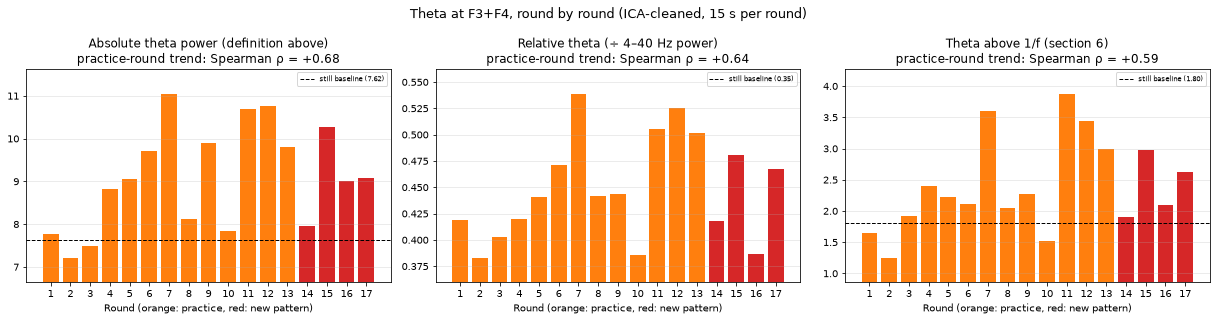

,round,pattern,theta F3 (dB µV²),theta F4 (dB µV²),theta F3+F4 (dB µV²),relative theta F3+F4,theta above 1/f F3+F4 (dB)
0,1,practice,7.755,7.778,7.767,0.419,1.64
1,2,practice,7.631,6.752,7.213,0.383,1.25
2,3,practice,8.255,6.543,7.483,0.403,1.92
3,4,practice,9.058,8.581,8.826,0.420,2.40
4,5,practice,10.070,7.720,9.052,0.441,2.23
5,6,practice,9.386,10.026,9.718,0.471,2.11
6,7,practice,12.447,8.988,11.053,0.539,3.60
7,8,practice,8.497,7.715,8.123,0.442,2.05
8,9,practice,10.181,9.599,9.900,0.444,2.27
9,10,practice,8.000,7.689,7.847,0.386,1.52


,theta F3 (dB µV²),theta F4 (dB µV²),theta F3+F4 (dB µV²)
Baseline (still),7.67,7.56,7.62
Early practice (rounds 1–4),8.21,7.49,7.87
Middle practice (rounds 5–9),10.33,8.91,9.68
Late practice (rounds 10–13),9.86,9.98,9.92
New pattern (rounds 14–17),9.85,8.33,9.16


In [17]:
from processing.analysis import BANDS, relative_power

rel_rows = []
for i in range(len(ROUNDS)):
    sp = roi_spectrum(window_spectra(periods[f"Round {i + 1}"]), THETA_CHANNELS)
    rel_rows.append(relative_power(sp, BANDS["theta"])[-1])

theta_table = pd.DataFrame({
    "round": range(1, len(ROUNDS) + 1),
    "pattern": PATTERN,
    "theta F3 (dB µV²)": [db(theta_welch[f"Round {i}"]["F3"]) for i in range(1, len(ROUNDS) + 1)],
    "theta F4 (dB µV²)": [db(theta_welch[f"Round {i}"]["F4"]) for i in range(1, len(ROUNDS) + 1)],
    "theta F3+F4 (dB µV²)": [db(theta_welch[f"Round {i}"][THETA_SITE]) for i in range(1, len(ROUNDS) + 1)],
    "relative theta F3+F4": rel_rows,
    "theta above 1/f F3+F4 (dB)": per_round["theta_F3+F4_dB"].values,
}).round(3)
baseline_row = {"theta F3+F4 (dB µV²)": db(theta_welch["Baseline (still)"][THETA_SITE]),
                "relative theta F3+F4": relative_power(roi_spectrum(window_spectra(periods["Baseline (still)"]), THETA_CHANNELS), BANDS["theta"])[-1],
                "theta above 1/f F3+F4 (dB)": base_vals["theta_F3+F4_dB"]}

practice_rows = theta_table[theta_table.pattern == "practice"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col, title in zip(axes, ["theta F3+F4 (dB µV²)", "relative theta F3+F4", "theta above 1/f F3+F4 (dB)"],
                          ["Absolute theta power (definition above)", "Relative theta (÷ 4–40 Hz power)", "Theta above 1/f (section 6)"]):
    rho = spearmanr(practice_rows["round"], practice_rows[col]).correlation
    ax.bar(theta_table["round"], theta_table[col], color=["C1" if p == "practice" else "C3" for p in PATTERN])
    ax.axhline(baseline_row[col], color="k", ls="--", lw=1, label=f"still baseline ({baseline_row[col]:.2f})")
    lo, hi = theta_table[col].min(), theta_table[col].max()
    ax.set_ylim(lo - 0.15 * (hi - lo), hi + 0.15 * (hi - lo))
    ax.set_xticks(theta_table["round"])
    ax.set_xlabel("Round (orange: practice, red: new pattern)")
    ax.set_title(f"{title}\npractice-round trend: Spearman ρ = {rho:+.2f}")
    ax.legend(fontsize=7)
    ax.grid(axis="y", alpha=0.3)
fig.suptitle(f"Theta at {THETA_SITE}, round by round (ICA-cleaned, 15 s per round)", fontsize=13)
fig.tight_layout()
plt.show()

groups = {"Baseline (still)": ["Baseline (still)"]}
groups.update({g: [f"Round {i + 1}" for i in idx] for g, idx in GROUPS.items()})
group_theta = pd.DataFrame({
    ch: [db(np.mean([theta_welch[p][ch] for p in members])) for members in groups.values()]
    for ch in ["F3", "F4", THETA_SITE]
}, index=list(groups)).round(2)
group_theta.columns = [f"theta {c} (dB µV²)" for c in group_theta.columns]
display(theta_table)
display(group_theta)

### 7.3 Every channel

Theta power is also measured on every channel (the band plots and per-channel bars in sections 3–5),
so the same check is repeated for all of them.

**Why this plot:** it shows whether a theta increase is specific to the frontal channels or happens
across the whole head, which would point to something global (time on task, arousal) rather than
frontal effort.

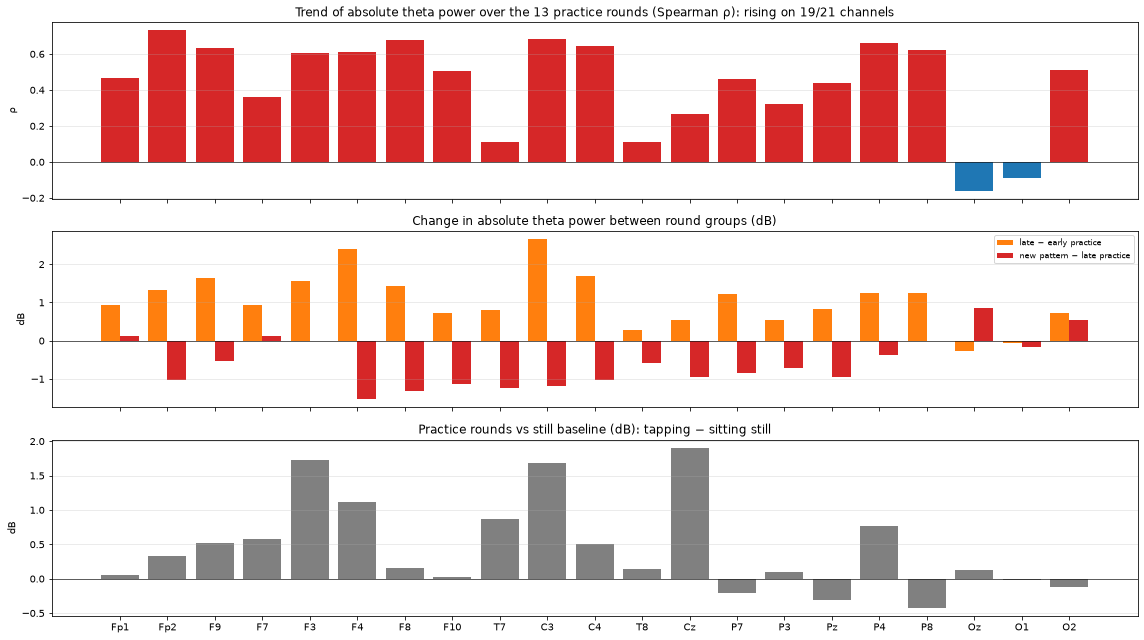

Rising over practice (ρ > 0): 19/21 channels; median ρ +0.51
Late − early practice: higher on 19/21 channels, median +0.94 dB
New pattern − late practice: higher on 5/21 channels, median -0.72 dB
Practice − baseline: higher on 16/21 channels, median +0.16 dB


In [18]:
channels = [c for c in clean_span.ch_names]
rounds_db = np.array([[db(theta_welch[f"Round {i + 1}"][c]) for c in channels] for i in range(len(ROUNDS))])
practice_idx = [i for i, p in enumerate(PATTERN) if p == "practice"]
trend = np.array([spearmanr(range(len(practice_idx)), rounds_db[practice_idx, j]).correlation for j in range(len(channels))])
late = rounds_db[list(GROUPS["Late practice (rounds 10–13)"])].mean(axis=0)
early = rounds_db[list(GROUPS["Early practice (rounds 1–4)"])].mean(axis=0)
new = rounds_db[list(GROUPS["New pattern (rounds 14–17)"])].mean(axis=0)
base_db = np.array([db(theta_welch["Baseline (still)"][c]) for c in channels])

x = np.arange(len(channels))
fig, axes = plt.subplots(3, 1, figsize=(16, 9), sharex=True)
axes[0].bar(x, trend, color=["C3" if v > 0 else "C0" for v in trend])
axes[0].set_title(f"Trend of absolute theta power over the 13 practice rounds (Spearman ρ): rising on "
                  f"{(trend > 0).sum()}/{len(channels)} channels")
axes[0].set_ylabel("ρ")
axes[1].bar(x - 0.2, late - early, 0.4, label="late − early practice", color="C1")
axes[1].bar(x + 0.2, new - late, 0.4, label="new pattern − late practice", color="C3")
axes[1].set_title("Change in absolute theta power between round groups (dB)")
axes[1].set_ylabel("dB")
axes[1].legend(fontsize=8)
axes[2].bar(x, rounds_db[practice_idx].mean(axis=0) - base_db, color="0.5")
axes[2].set_title("Practice rounds vs still baseline (dB): tapping − sitting still")
axes[2].set_ylabel("dB")
for ax in axes:
    ax.axhline(0, color="k", lw=0.6)
    ax.grid(axis="y", alpha=0.3)
axes[-1].set_xticks(x, channels)
fig.tight_layout()
plt.show()
print(f"Rising over practice (ρ > 0): {(trend > 0).sum()}/{len(channels)} channels; median ρ {np.median(trend):+.2f}")
print(f"Late − early practice: higher on {(late > early).sum()}/{len(channels)} channels, median {np.median(late - early):+.2f} dB")
print(f"New pattern − late practice: higher on {(new > late).sum()}/{len(channels)} channels, median {np.median(new - late):+.2f} dB")
print(f"Practice − baseline: higher on {(rounds_db[practice_idx].mean(axis=0) > base_db).sum()}/{len(channels)} channels, "
      f"median {np.median(rounds_db[practice_idx].mean(axis=0) - base_db):+.2f} dB")

### 7.4 Is theta power increasing?

**Yes, over the practice rounds. Absolute theta power at F3+F4 rises by about 2 dB (≈60% more
power) from early to late practice, the rise appears under all three definitions, and it happens
on almost every channel. It does not increase for the new pattern; it drops.**

| Theta power at F3+F4 (absolute, dB µV²) | Value | Change |
|---|---|---|
| Still baseline | 7.62 | |
| Early practice (rounds 1–4) | 7.87 | +0.3 vs baseline |
| Middle practice (rounds 5–9) | 9.68 | +1.8 vs early |
| Late practice (rounds 10–13) | 9.92 | **+2.05 vs early** |
| New pattern (rounds 14–17) | 9.16 | **−0.76 vs late** |

- **Same direction under every definition:** the trend over the 13 practice rounds is ρ = +0.68
  (absolute power), +0.64 (relative theta) and +0.59 (theta above 1/f). So the rise is in theta
  itself, not an artifact of normalizing by other bands or by the 1/f background.
- **Computed correctly:** the Welch integral and the variance of the exactly 4–8 Hz band-passed
  signal (Parseval) agree within 0.1 dB on average (at most 0.5 dB) across all 18 periods.
- **Across the head:** theta rises over practice on 19 of 21 channels (median ρ = +0.51; late − early
  median +0.94 dB); only Oz and O1 don't. During tapping, theta is highest relative to the still baseline at
  F3, C3, Cz and F4 (+1.1 to +1.9 dB), the frontal and central sites, and roughly unchanged at the back
  of the head.
- **New pattern:** theta is lower than in late practice on 16 of 21 channels (median −0.72 dB).

What this means for the hypotheses:
- **Learning (hypothesis 1) predicted theta would fall** as the pattern became familiar. It rose
  instead, steadily, under every definition.
- **New pattern (hypothesis 2) predicted theta would rise** when the pattern changed. It fell.
- Theta here behaves like a **time-on-task / sustained-practice** signal (it builds up across the
  practice rounds and is spread across the head) rather than a measure of moment-to-moment effort.
  This matches Gevins et al. (1997), who found frontal theta increased with practice. In this session
  the effort-like signal is parietal **alpha**, which drops when the new pattern starts (section 6).